In [1]:
# Import libraries
import pandas as pd
import seaborn as sns
import sklearn.preprocessing as preproc
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GriSdearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import scipy.stats as scipy_stats
from scipy.stats import shapiro, ttest_ind, f_oneway, pearsonr
import statsmodels.api as sm
import sklearn.preprocessing as preproc
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, Normalizer


In [2]:
# Read Dataset
data = pd.read_excel('Fisheries_CA2_Dataset.xlsx')

In [3]:
# Check first 5 rows
data.head()

,County,Avg_Fisher_Income_EUR,Fuel_Cost_Index,Port_Accessibility_Score,Fish_Stock_Index,Water_Quality_Score,Weather_Risk_Index,Illegal_Fishing_Rate_%,Aquaculture_Investment_EUR,Export_Demand_Level,Vessel_Type,Sustainability_Score,Predicted_Annual_Revenue_EUR
0,Waterford,81077.05,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,High,Longliner,99.44,201495.28
1,Clare,76078.84,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,Average,Trawler,115.02,202484.46
2,Cork,50576.94,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,Low,Longliner,61.75,107997.00
3,Dublin,73236.59,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,Average,Small Boat,115.48,188797.98
4,Dublin,69185.63,109.94,5.41,5.27,8.59,5.38,5.72,91268.62,Average,NaN,110.90,147138.23


In [4]:
# Shape of the data, number of columns and rows
data.shape

(2080, 13)

In [5]:
# Data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2080 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   County                        2059 non-null   object 
 1   Avg_Fisher_Income_EUR         2059 non-null   float64
 2   Fuel_Cost_Index               2059 non-null   float64
 3   Port_Accessibility_Score      2059 non-null   float64
 4   Fish_Stock_Index              2059 non-null   float64
 5   Water_Quality_Score           2059 non-null   float64
 6   Weather_Risk_Index            2059 non-null   float64
 7   Illegal_Fishing_Rate_%        2059 non-null   float64
 8   Aquaculture_Investment_EUR    2059 non-null   float64
 9   Export_Demand_Level           2059 non-null   object 
 10  Vessel_Type                   2059 non-null   object 
 11  Sustainability_Score          2059 non-null   float64
 12  Predicted_Annual_Revenue_EUR  2059 non-null   float64
dtypes: 

In [6]:
# Rename and shorten the columns
# Leave first letters and type of variable
data.rename(columns = ({
    'Avg_Fisher_Income_EUR': 'afi_eur', 
     'Fuel_Cost_Index': 'fc_index', 
     'Port_Accessibility_Score': 'pa_score',
     'Fish_Stock_Index': 'fs_index',
     'Water_Quality_Score': 'wq_score',
     'Weather_Risk_Index': 'wr_index',
     'Illegal_Fishing_Rate_%': 'ifr_percen',
     'Aquaculture_Investment_EUR': 'ai_eur',
     'Export_Demand_Level': 'ed_level',
     'Vessel_Type': 'ves_type',
     'Sustainability_Score': 'sus_score',
     'Predicted_Annual_Revenue_EUR': 'par_eur'
}), inplace=True)

In [7]:
# Check changes
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,Waterford,81077.05,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,High,Longliner,99.44,201495.28
1,Clare,76078.84,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,Average,Trawler,115.02,202484.46
2,Cork,50576.94,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,Low,Longliner,61.75,107997.00
3,Dublin,73236.59,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,Average,Small Boat,115.48,188797.98
4,Dublin,69185.63,109.94,5.41,5.27,8.59,5.38,5.72,91268.62,Average,NaN,110.90,147138.23


In [8]:
# Describe statistical information
data.describe()

,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,sus_score,par_eur
count,2059.000000,2059.000000,2059.000000,2059.000000,2059.000000,2059.000000,2059.000000,2059.000000,2059.000000,2059.000000
mean,72511.124876,100.088698,5.969354,5.955352,7.006960,4.114594,4.914230,109863.973458,103.040413,174679.905537
std,11845.548793,14.895004,1.980090,1.943586,1.457452,1.896673,2.002769,22225.645739,22.356924,43489.897248
min,35298.260000,52.680000,1.000000,1.000000,2.100000,1.000000,0.000000,38247.500000,25.490000,28148.810000
25%,64806.695000,90.280000,4.620000,4.640000,6.020000,2.695000,3.565000,95427.780000,88.230000,145903.220000
50%,72646.920000,100.280000,6.000000,5.940000,7.030000,4.060000,4.850000,110054.900000,103.500000,176154.600000
75%,80310.940000,109.885000,7.340000,7.260000,8.000000,5.430000,6.305000,125296.360000,118.050000,204900.420000
max,107127.470000,145.030000,10.000000,10.000000,10.000000,10.000000,11.790000,170958.000000,172.740000,303843.800000


In [9]:
# Null values 
data.isnull().sum()

County        21
afi_eur       21
fc_index      21
pa_score      21
fs_index      21
wq_score      21
wr_index      21
ifr_percen    21
ai_eur        21
ed_level      21
ves_type      21
sus_score     21
par_eur       21
dtype: int64

In [10]:
# Duplicates
data.duplicated().sum()

np.int64(0)

In [11]:
# Drop duplicates
data = data.drop_duplicates()

# HANDLING MISSING VALUES

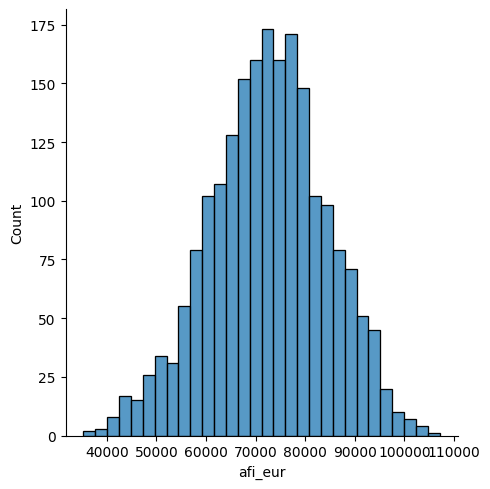

In [12]:
# Afi_eur distribution
sns.displot(data, x='afi_eur');

<Axes: xlabel='afi_eur'>

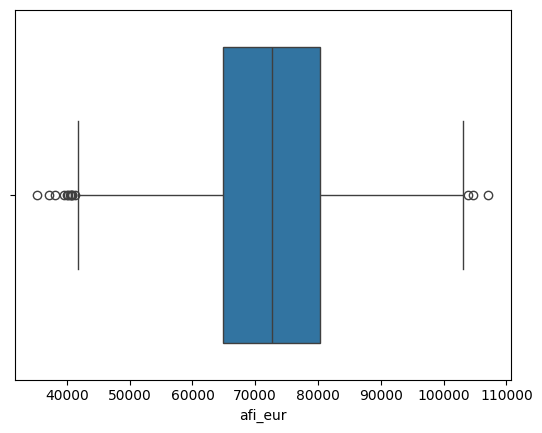

In [13]:
# afi_eur outliers
sns.boxplot(data=data, x='afi_eur')

In [14]:
# chosen method  linear interpolation
data['afi_eur'] = data['afi_eur'].interpolate(method='linear', limit_direction='forward')

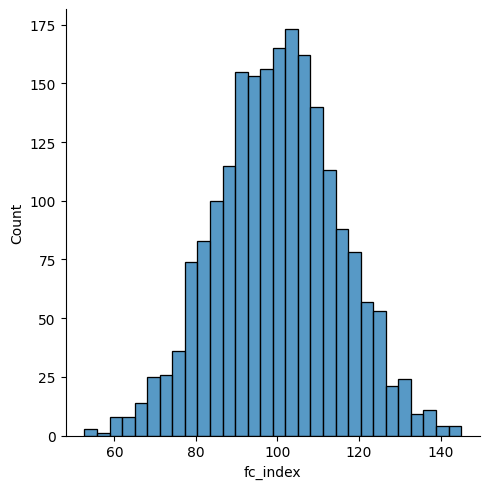

In [15]:
# fc_index distribution
sns.displot(data, x='fc_index');

<Axes: xlabel='fc_index'>

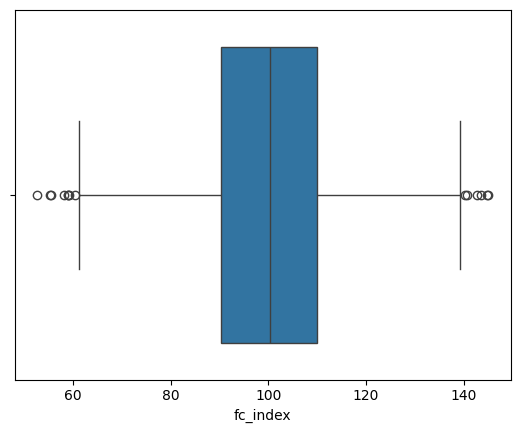

In [16]:
# fc_index outliers 
sns.boxplot(data=data, x='fc_index')

In [17]:
# chosen method  linear interpolation
data['fc_index'] = data['fc_index'].interpolate(method='linear', limit_direction='forward')

In [18]:
# Check if changes are being made
data.isnull().sum()

County        21
afi_eur        0
fc_index       0
pa_score      21
fs_index      21
wq_score      21
wr_index      21
ifr_percen    21
ai_eur        21
ed_level      21
ves_type      21
sus_score     21
par_eur       21
dtype: int64

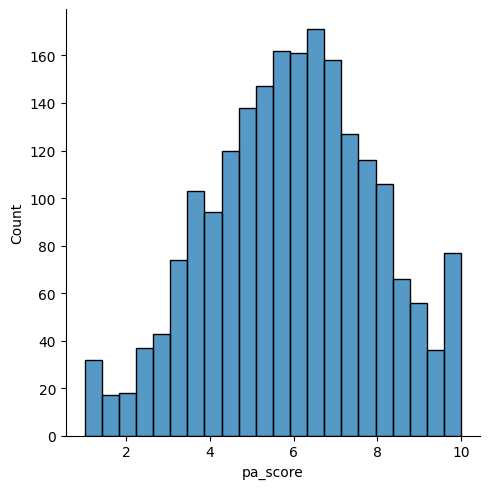

In [19]:
# pa_score distribution
sns.displot(data, x='pa_score');

<Axes: xlabel='pa_score'>

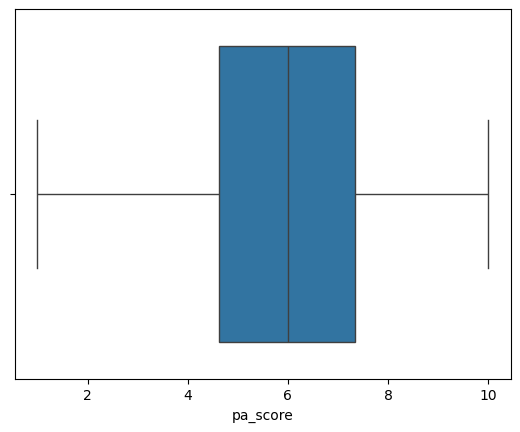

In [20]:
# pa_score outliers
sns.boxplot(data=data, x='pa_score')

In [21]:
# chosen method  forward fill
data['pa_score'] = data['pa_score'].fillna(method='ffill')

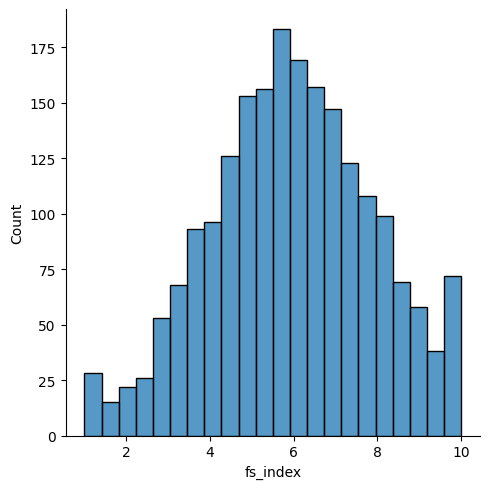

In [22]:
# fs_index distribution
sns.displot(data, x='fs_index');

<Axes: xlabel='fs_index'>

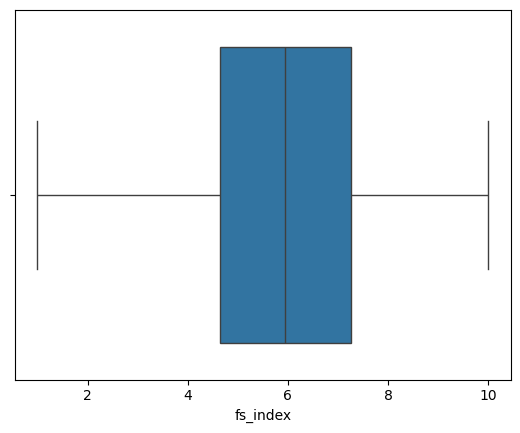

In [23]:
# fs_index outliers
sns.boxplot(data=data, x='fs_index')

In [24]:
# chosen method  forward fill
data['fs_index'] = data['fs_index'].fillna(method='ffill')

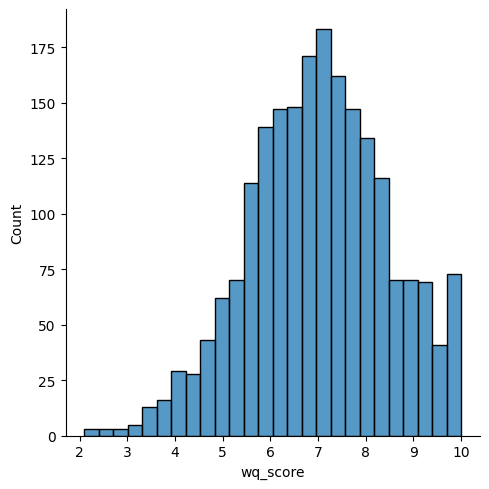

In [25]:
# wq_score distribution
sns.displot(data, x='wq_score');

<Axes: xlabel='wq_score'>

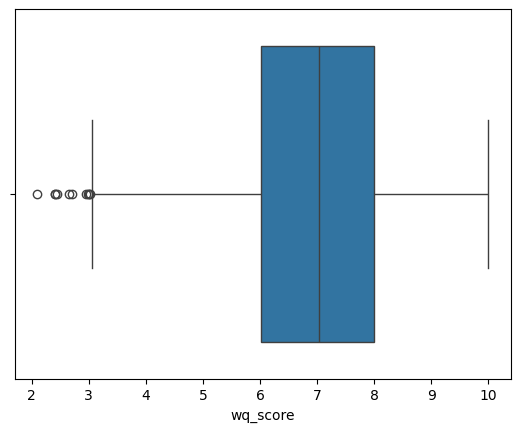

In [26]:
# wq_score outliers
sns.boxplot(data=data, x='wq_score')

In [27]:
#chosen method  interpolation
data['wq_score'] = data['wq_score'].interpolate(method='linear', limit_direction='forward')

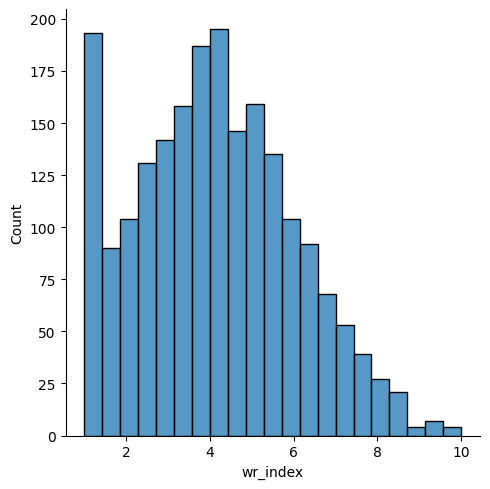

In [28]:
# wr_index distribution
sns.displot(data, x='wr_index');

<Axes: xlabel='wr_index'>

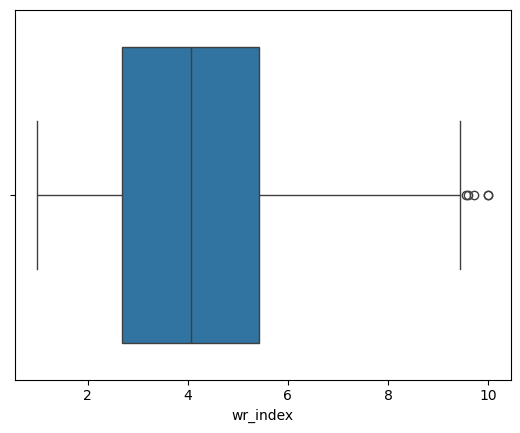

In [29]:
# wr_index outliers
sns.boxplot(data=data, x='wr_index')

In [30]:
# chosen method  forward fill
data['wr_index'] = data['wr_index'].fillna(method='ffill')

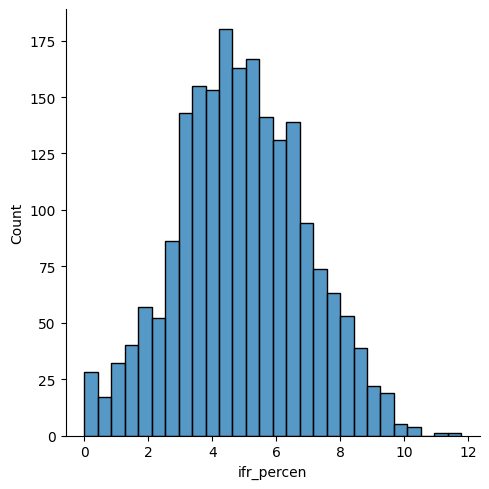

In [31]:
# ifr_percen distribution
sns.displot(data, x='ifr_percen');

<Axes: xlabel='ifr_percen'>

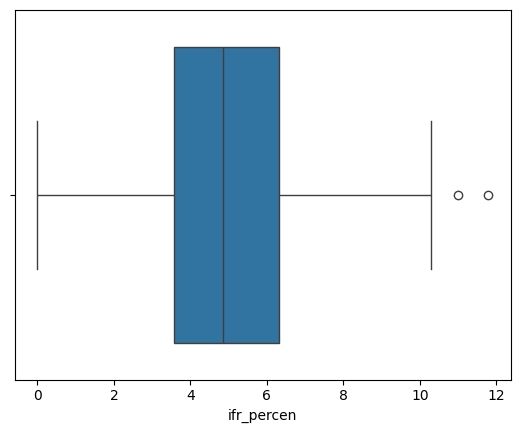

In [32]:
# ifr_percen outliers
sns.boxplot(data=data, x='ifr_percen')

In [33]:
# chosen method  backfill
data['ifr_percen'] = data['ifr_percen'].fillna(method='bfill')

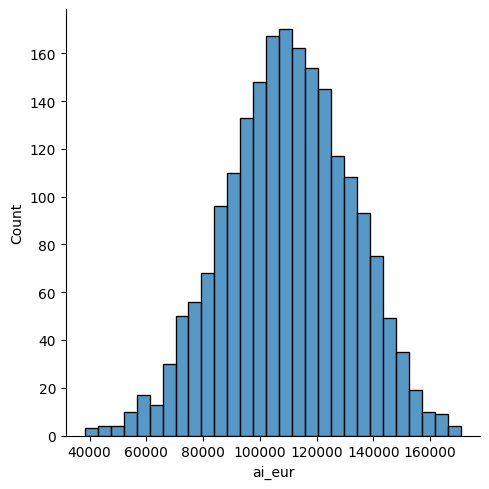

In [34]:
# ai_eur distribution
sns.displot(data, x='ai_eur');

<Axes: xlabel='ai_eur'>

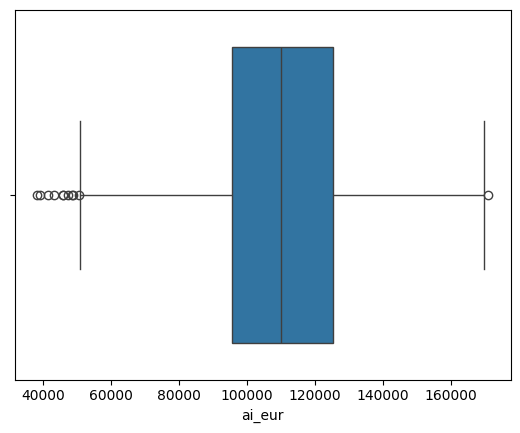

In [35]:
# ai_eur outliers
sns.boxplot(data=data, x='ai_eur')

In [36]:
# chosen method linear interpolation
data['ai_eur'] = data['ai_eur'].interpolate(method='linear', limit_direction='forward')

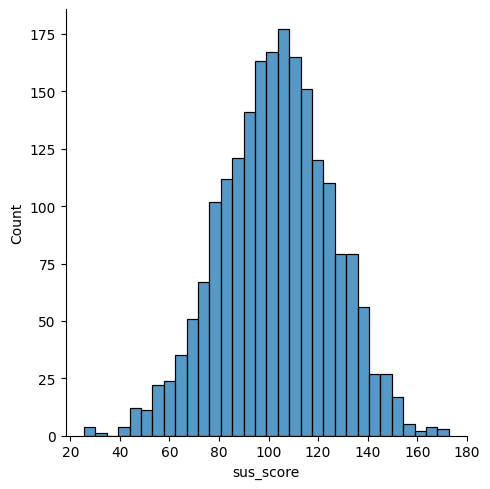

In [37]:
# sus_score distribution
sns.displot(data, x='sus_score');

<Axes: xlabel='sus_score'>

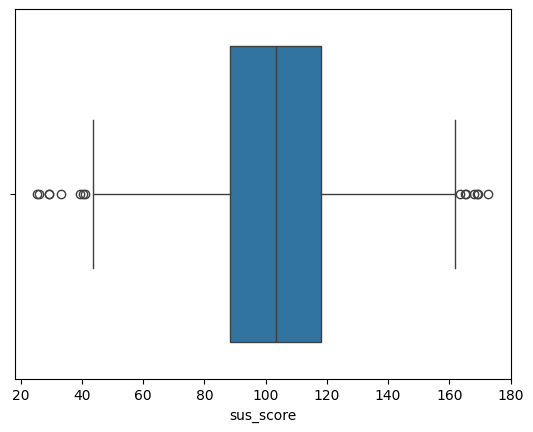

In [38]:
# sus_score outliers
sns.boxplot(data=data, x='sus_score')

In [39]:
# chosen method linear interpolation
data['sus_score'] = data['sus_score'].interpolate(method='linear', limit_direction='forward')

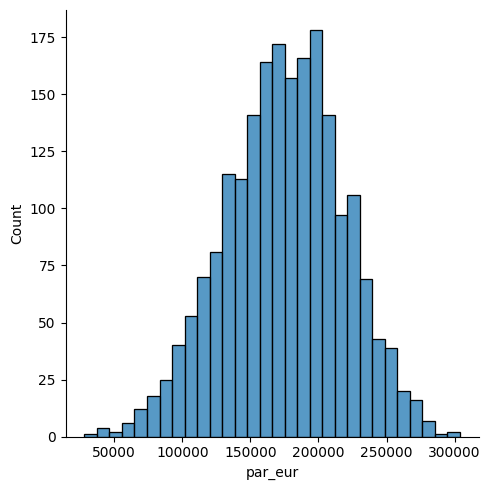

In [40]:
# par_eur distribution
sns.displot(data, x='par_eur');

<Axes: xlabel='par_eur'>

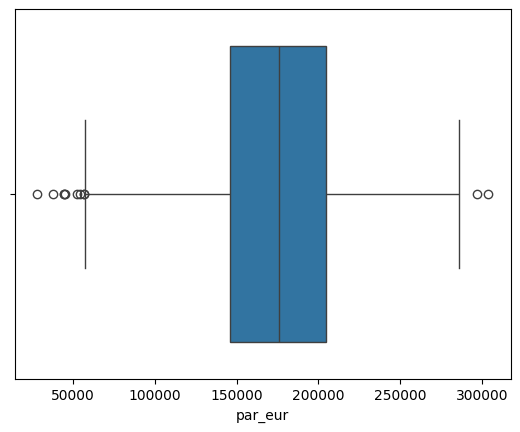

In [41]:
# par_eur outliers
sns.boxplot(data=data, x='par_eur')

In [42]:
# chosen method interpolation
# did not run 
#data['par_eur'] = data['par_eur'].interpolate(method='linear', limit_direction='forward')

In [43]:
# check null values after handling missing values
data.isnull().sum()

County        21
afi_eur        0
fc_index       0
pa_score       0
fs_index       0
wq_score       0
wr_index       0
ifr_percen     0
ai_eur         0
ed_level      21
ves_type      21
sus_score      0
par_eur       21
dtype: int64

In [44]:
# Drop missing values from categorical data and target variable columns
# Avoid bias
data.dropna(inplace = True)

In [45]:
# Check missing values
data.isnull().sum()

County        0
afi_eur       0
fc_index      0
pa_score      0
fs_index      0
wq_score      0
wr_index      0
ifr_percen    0
ai_eur        0
ed_level      0
ves_type      0
sus_score     0
par_eur       0
dtype: int64

# Duplicates

In [46]:
# Check duplicates after handling missing values 
data.duplicated().sum()

np.int64(0)

In [47]:
# Shape after dropping missing values
data.shape

(1996, 13)

In [48]:
# Drop duplicates if necesary 
data = data.drop_duplicates()

In [49]:
# Shape after dropping duplicates
data.shape

(1996, 13)

# ENCODING

In [50]:
# Name encoder as label encoder and ordinal encoder
le = preproc.LabelEncoder()
oe = preproc.OrdinalEncoder()

In [51]:
# Unique values from County
data['County'].unique()

array(['Waterford', 'Clare', 'Cork', 'Dublin', 'Mayo', 'Wexford',
       'Galway', 'Donegal', 'Limerick', 'Kerry'], dtype=object)

In [52]:
# Transform 'County' to label encoder
data['County'] = le.fit_transform(data['County'])

In [53]:
# Check if values correspond to the number of counties
data['County'].unique()

array([8, 0, 1, 3, 7, 9, 4, 2, 6, 5])

In [54]:
# Unique values from ed_level
data['ed_level'].unique()

array(['High', 'Average', 'Low'], dtype=object)

In [55]:
# Transform 'ed_level' to ordinal encoder
data['ed_level'] = oe.fit_transform(data[['ed_level']])

In [56]:
# Check if values correspond to the number of levels
data['ed_level'].unique()

array([1., 0., 2.])

In [57]:
# Unique values from ves_type
data['ves_type'].unique()

array(['Longliner', 'Trawler', 'Small Boat', 'Purse Seine', 'Gillnetter'],
      dtype=object)

In [58]:
# Transform 'ves_type' to label encoder
data['ves_type'] = le.fit_transform(data['ves_type'])

In [59]:
# Check if values correspond to the number of types
data['ves_type'].unique()

array([1, 4, 3, 2, 0])

In [60]:
# Check changes made
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,81077.05,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,1.0,1,99.44,201495.28
1,0,76078.84,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,0.0,4,115.02,202484.46
2,1,50576.94,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,2.0,1,61.75,107997.00
3,3,73236.59,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,0.0,3,115.48,188797.98
5,1,81472.19,86.89,7.72,6.41,5.69,1.00,1.78,143748.45,1.0,1,102.84,208188.97


In [61]:
# describe statistical information
data.describe()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
count,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000
mean,4.452405,72530.396561,99.937891,5.951919,5.952144,7.021473,4.111728,4.918442,109665.200271,0.796092,2.010521,102.982761,174706.128056
std,2.888442,11887.094403,14.923290,1.983641,1.950548,1.448316,1.902403,2.006820,22241.549928,0.838907,1.417891,22.331643,43680.088957
min,0.000000,35298.260000,52.680000,1.000000,1.000000,2.100000,1.000000,0.000000,38247.500000,0.000000,0.000000,25.490000,28148.810000
25%,2.000000,64850.582500,90.040000,4.600000,4.630000,6.047500,2.690000,3.567500,94918.332500,0.000000,1.000000,88.280000,145851.880000
50%,4.500000,72691.780000,99.885000,5.980000,5.935000,7.050000,4.050000,4.850000,110037.730000,1.000000,2.000000,103.300000,176190.395000
75%,7.000000,80353.075000,109.607500,7.332500,7.262500,8.012500,5.432500,6.330000,125175.907500,2.000000,3.000000,117.945000,204930.072500
max,9.000000,107127.470000,145.030000,10.000000,10.000000,10.000000,10.000000,11.790000,170958.000000,2.000000,4.000000,172.740000,303843.800000


In [62]:
# Number of rows and columns
data.shape

(1996, 13)

In [63]:
# Number of duplicates
data.duplicated().sum()

np.int64(0)

In [64]:
# Drop duplicates if needed
data = data.drop_duplicates()

In [65]:
# Number of rows and columns after removing duplicates
data.shape

(1996, 13)

# STATISTICAL TECHNIQUES

# 1. Descriptive Analysis

In [68]:
# Create a copy of data to make the statistical analysis
stats = data.copy()
# Check 5 first rows
stats.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,81077.05,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,1.0,1,99.44,201495.28
1,0,76078.84,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,0.0,4,115.02,202484.46
2,1,50576.94,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,2.0,1,61.75,107997.00
3,3,73236.59,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,0.0,3,115.48,188797.98
5,1,81472.19,86.89,7.72,6.41,5.69,1.00,1.78,143748.45,1.0,1,102.84,208188.97


In [214]:
# Describe statistical information
stats.describe()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
count,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000,1996.000000
mean,4.452405,72530.396561,99.937891,5.951919,5.952144,7.021473,4.111728,4.918442,109665.200271,0.796092,2.010521,102.982761,174706.128056
std,2.888442,11887.094403,14.923290,1.983641,1.950548,1.448316,1.902403,2.006820,22241.549928,0.838907,1.417891,22.331643,43680.088957
min,0.000000,35298.260000,52.680000,1.000000,1.000000,2.100000,1.000000,0.000000,38247.500000,0.000000,0.000000,25.490000,28148.810000
25%,2.000000,64850.582500,90.040000,4.600000,4.630000,6.047500,2.690000,3.567500,94918.332500,0.000000,1.000000,88.280000,145851.880000
50%,4.500000,72691.780000,99.885000,5.980000,5.935000,7.050000,4.050000,4.850000,110037.730000,1.000000,2.000000,103.300000,176190.395000
75%,7.000000,80353.075000,109.607500,7.332500,7.262500,8.012500,5.432500,6.330000,125175.907500,2.000000,3.000000,117.945000,204930.072500
max,9.000000,107127.470000,145.030000,10.000000,10.000000,10.000000,10.000000,11.790000,170958.000000,2.000000,4.000000,172.740000,303843.800000


In [69]:
# Select all columns for analysis
variables = stats.columns


## Central tendency

In [72]:
# Central tendency metrics for all columns
central_tendency = pd.DataFrame({
    'Mean': stats[variables].mean(),
    'Median': stats[variables].median(),
    'Mode': stats[variables].mode().iloc[0]
})

central_tendency

,Mean,Median,Mode
County,4.452405,4.500,0.00
afi_eur,72530.396561,72691.780,35298.26
fc_index,99.937891,99.885,102.11
pa_score,5.951919,5.980,10.00
fs_index,5.952144,5.935,10.00
wq_score,7.021473,7.050,10.00
wr_index,4.111728,4.050,1.00
ifr_percen,4.918442,4.850,0.00
ai_eur,109665.200271,110037.730,38247.50
ed_level,0.796092,1.000,0.00


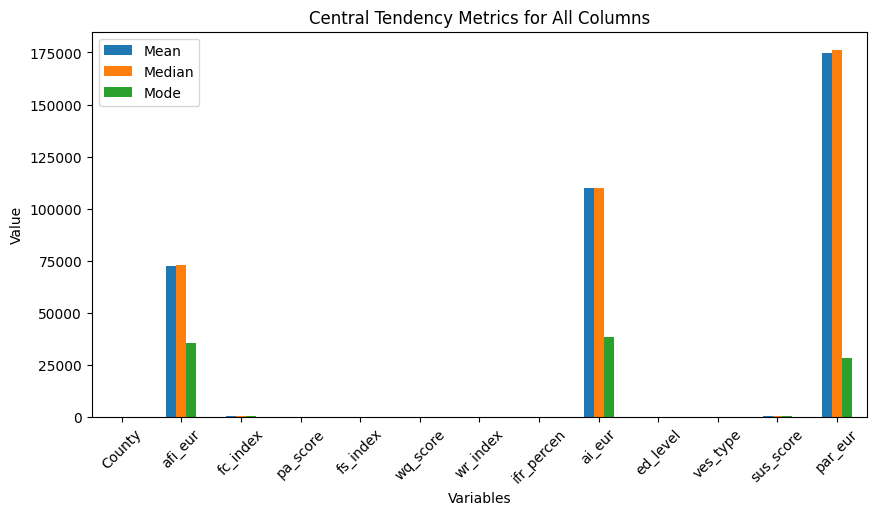

In [73]:
# Visualization of central tendency metrics
central_tendency.plot(kind='bar',figsize=(10,5))

plt.title('Central Tendency Metrics for All Columns')
plt.xlabel('Variables')
plt.ylabel('Value')

plt.xticks(rotation=45)

plt.show()

## Variation metrics

In [74]:
# Variation metrics for all columns
variation_metrics = pd.DataFrame({
    'Range': stats[variables].max() - stats[variables].min(),
    'Variance': stats[variables].var(),
    'Standard Deviation': stats[variables].std(),
    'IQR': stats[variables].quantile(0.75) - stats[variables].quantile(0.25)
})

variation_metrics

,Range,Variance,Standard Deviation,IQR
County,9.00,8.343097e+00,2.888442,5.0000
afi_eur,71829.21,1.413030e+08,11887.094403,15502.4925
fc_index,92.35,2.227046e+02,14.923290,19.5675
pa_score,9.00,3.934830e+00,1.983641,2.7325
fs_index,9.00,3.804636e+00,1.950548,2.6325
wq_score,7.90,2.097619e+00,1.448316,1.9650
wr_index,9.00,3.619136e+00,1.902403,2.7425
ifr_percen,11.79,4.027325e+00,2.006820,2.7625
ai_eur,132710.50,4.946865e+08,22241.549928,30257.5750
ed_level,2.00,7.037642e-01,0.838907,2.0000


## Probabilities

In [75]:
# Probability of revenue being above the mean
mean_revenue = stats['par_eur'].mean()

prob_high_revenue = (stats['par_eur'] > mean_revenue).mean() * 100

print('Mean Revenue:', round(mean_revenue, 2))
print('Probability of revenue being above the mean:',round(prob_high_revenue, 2),'%')

Mean Revenue: 174706.13
Probability of revenue being above the mean: 51.3 %


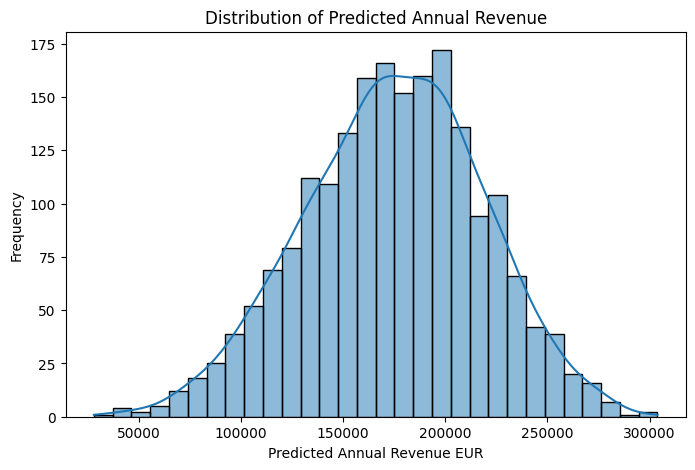

In [76]:
# Distribution of predicted annual revenue
plt.figure(figsize=(8, 5))

sns.histplot(stats['par_eur'], kde=True)

plt.title('Distribution of Predicted Annual Revenue')
plt.xlabel('Predicted Annual Revenue EUR')
plt.ylabel('Frequency')

plt.show()

In [77]:
# Probability distribution of export demand level
ed_probability = stats['ed_level'].value_counts(normalize=True) * 100

print('Probability distribution of Export Demand Level:')
print(ed_probability)

Probability distribution of Export Demand Level:
ed_level
0.0    47.444890
2.0    27.054108
1.0    25.501002
Name: proportion, dtype: float64


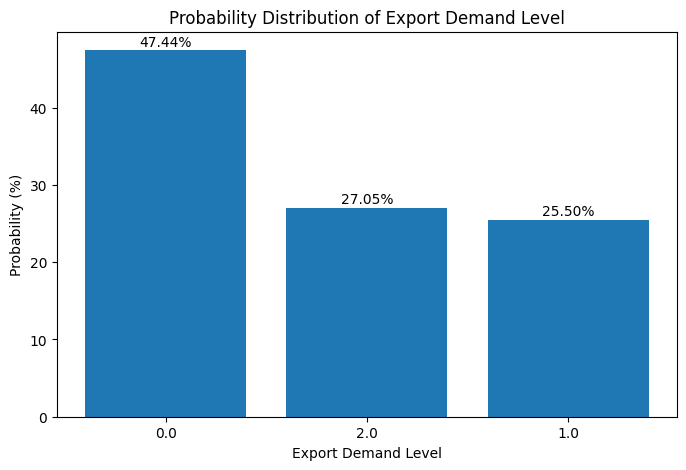

In [78]:
# Distribution of export demand level
plt.figure(figsize=(8,5))

plt.bar(ed_probability.index.astype(str),ed_probability.values)

plt.title('Probability Distribution of Export Demand Level')
plt.xlabel('Export Demand Level')
plt.ylabel('Probability (%)')

# Percentage labels
for i, value in enumerate(ed_probability.values):
    plt.text(i,value + 0.5,f'{value:.2f}%',ha='center')
plt.show()

In [79]:
# Probability of sustainability being above the mean
mean_sus = stats['sus_score'].mean()

prob_high_sus = (stats['sus_score'] > mean_sus).mean() * 100

print('Mean Sus:', round(mean_sus, 2))
print('Probability of sustainability being above the mean:',round(prob_high_sus, 2),'%')

Mean Sus: 102.98
Probability of sustainability being above the mean: 50.7 %


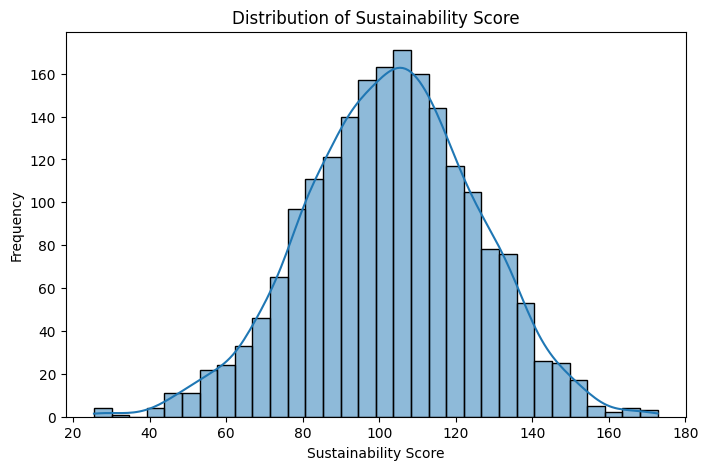

In [80]:
# Distribution of sustainability score
plt.figure(figsize=(8, 5))

sns.histplot(stats['sus_score'], kde=True)

plt.title('Distribution of Sustainability Score')
plt.xlabel('Sustainability Score')
plt.ylabel('Frequency')

plt.show()

# Normality Test for All Columns

In [81]:
from scipy.stats import shapiro

# Store results
normality_results = []

# Loop through all variables
for ft in variables:
    
    stat, p = shapiro(stats[ft])

    # Determine distribution
    if p > 0.05:
        distribution = 'Normal Distribution'
    else:
        distribution = 'Significant result'

    # Store results
    normality_results.append([ft,stat,p,distribution])

# Create DataFrame
normality_test = pd.DataFrame(
    normality_results,
    columns=['Variable','Shapiro Statistic','P-value','Distribution'])

# Display results
normality_test

,Variable,Shapiro Statistic,P-value,Distribution
0,County,0.934823,1.047419e-28,Significant result
1,afi_eur,0.997591,3.838974e-03,Significant result
2,fc_index,0.999313,7.005782e-01,Normal Distribution
3,pa_score,0.992551,1.538229e-08,Significant result
4,fs_index,0.993346,7.613716e-08,Significant result
5,wq_score,0.994102,3.841997e-07,Significant result
6,wr_index,0.980371,6.141957e-16,Significant result
7,ifr_percen,0.997369,1.928150e-03,Significant result
8,ai_eur,0.997858,8.973888e-03,Significant result
9,ed_level,0.755705,2.087498e-47,Significant result


# Skeweness test for all columns 

In [216]:
# Skewness test for all variables
skewness_results = []
for ft in variables:

    skew_value = stats[ft].skew()
    # Classify skewness
    if -0.5 <= skew_value <= 0.5:
        distribution = 'Symmetric'    
    elif (-1 <= skew_value < -0.5) or (0.5 < skew_value <= 1):
        distribution = 'Moderately Skewed'    
    else:
        distribution = 'Highly Skewed'

    # Store results
    skewness_results.append([ft,skew_value,distribution])
# Create DataFrame
skewness_test = pd.DataFrame(
    skewness_results,columns=['Variable','Skewness','Distribution'])
# Display results
skewness_test

,Variable,Skewness,Distribution
0,County,-0.001914,Symmetric
1,afi_eur,-0.133076,Symmetric
2,fc_index,0.017226,Symmetric
3,pa_score,-0.112615,Symmetric
4,fs_index,-0.082997,Symmetric
5,wq_score,-0.143439,Symmetric
6,wr_index,0.274319,Symmetric
7,ifr_percen,0.050921,Symmetric
8,ai_eur,-0.140059,Symmetric
9,ed_level,0.398408,Symmetric


# Outliers Test

In [217]:
# Outlier test for all variables using IQR

outlier_results = []
for ft in variables:
    # Calculate Q1 and Q3
    Q1 = stats[ft].quantile(0.25)
    Q3 = stats[ft].quantile(0.75)
    # Calculate IQR
    IQR = Q3 - Q1
    # Define lower and upper bounds
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)
    # Count outliers
    outliers = stats[(stats[ft] < lower_bound) |(stats[ft] > upper_bound)]

    num_outliers = len(outliers)
    # Classify variable
    if num_outliers > 0:
        distribution = 'Has Outliers'
    else:
        distribution = 'No Outliers'
    # Store results
    outlier_results.append([ft,num_outliers,distribution])

# Create DataFrame
outlier_test = pd.DataFrame(
    outlier_results,columns=['Variable','Number of Outliers','Outlier Status'])

# Display results
outlier_test

,Variable,Number of Outliers,Outlier Status
0,County,0,No Outliers
1,afi_eur,14,Has Outliers
2,fc_index,16,Has Outliers
3,pa_score,0,No Outliers
4,fs_index,0,No Outliers
5,wq_score,10,Has Outliers
6,wr_index,5,Has Outliers
7,ifr_percen,2,Has Outliers
8,ai_eur,10,Has Outliers
9,ed_level,0,No Outliers


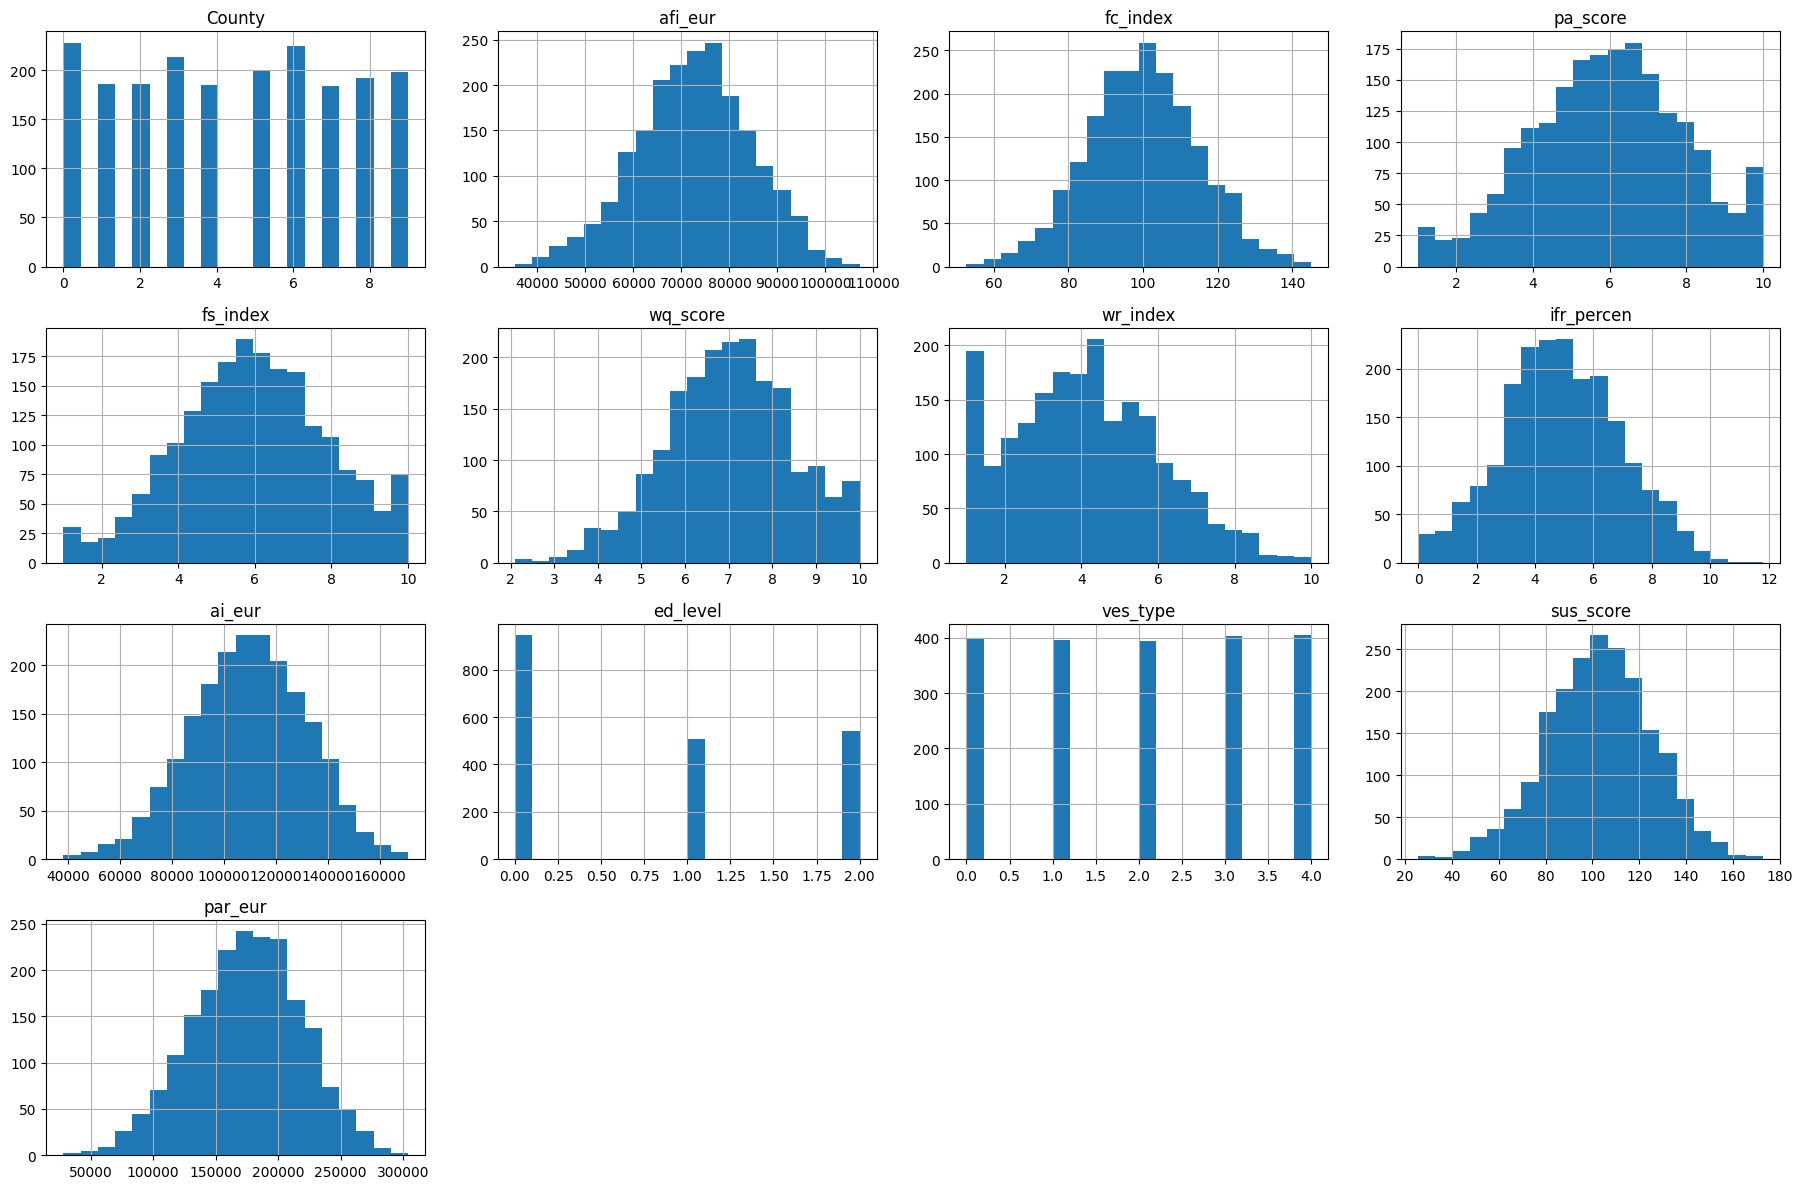

In [82]:
# Histograms to check columns distribution
stats.hist(figsize=(18,12), bins=20)
plt.tight_layout()
plt.show()

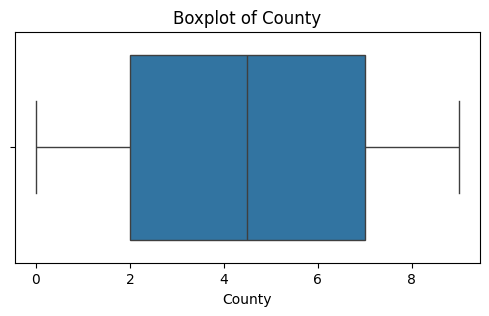

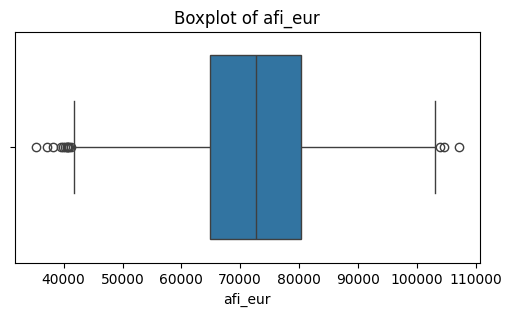

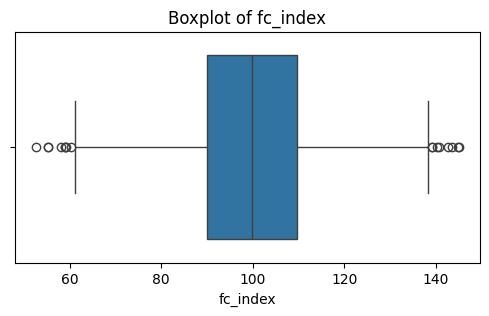

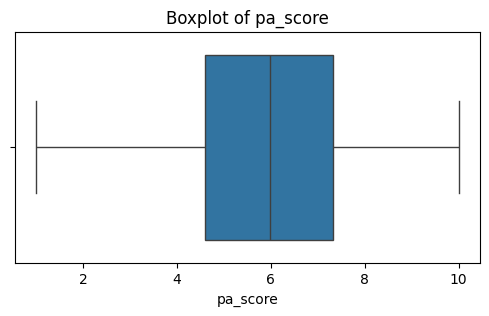

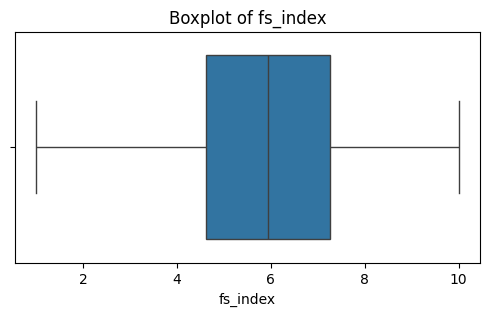

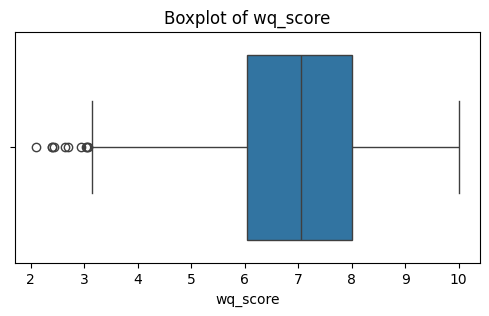

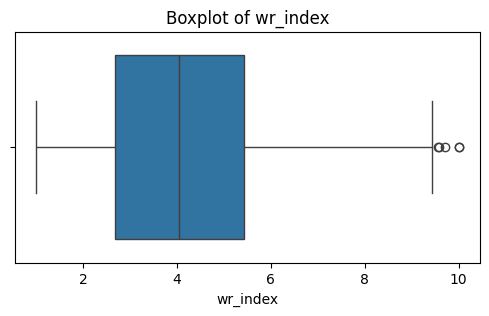

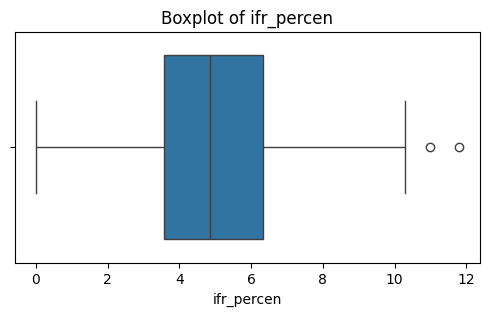

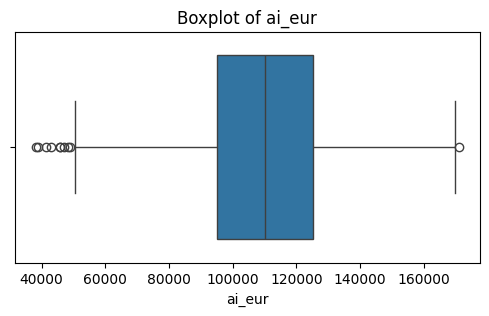

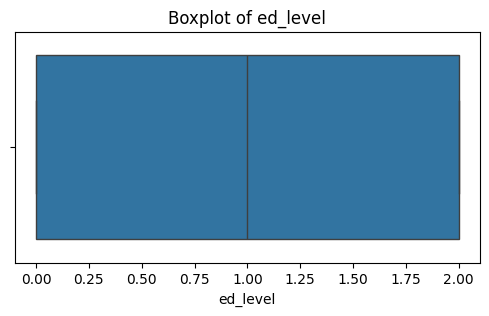

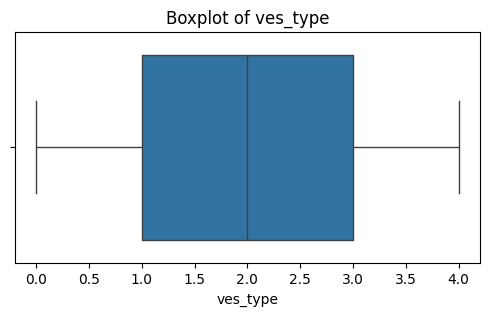

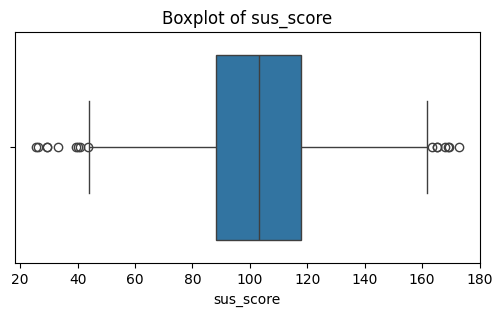

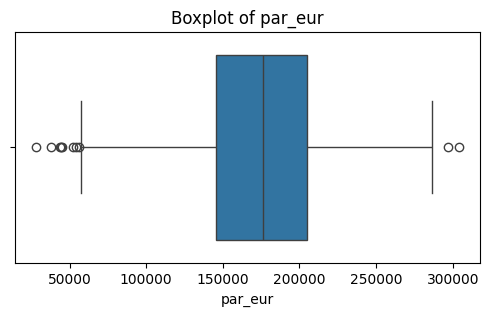

In [83]:
# Outliers of all columns
for ft in stats:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=stats[ft])
    plt.title(f'Boxplot of {ft}')
    plt.show()

# 3. Confidence Intervals

In [73]:
import scipy.stats as scipy_stats

In [74]:
# mean fuel cost for low sustainability vs high sustainability.
low_sus_fuel = stats[stats['sus_score'] <= stats['sus_score'].mean()]['fc_index']
high_sus_fuel = stats[stats['sus_score'] > stats['sus_score'].mean()]['fc_index']

In [75]:
# 95% confidence intervals
low_ci = scipy_stats.t.interval(
    0.95,
    len(low_sus_fuel)-1,
    loc=np.mean(low_sus_fuel),
    scale=scipy_stats.sem(low_sus_fuel)
)

high_ci = scipy_stats.t.interval(
    0.95,
    len(high_sus_fuel)-1,
    loc=np.mean(high_sus_fuel),
    scale=scipy_stats.sem(high_sus_fuel)
)


In [76]:
# Table with results
ci_results = pd.DataFrame({
    'Sample': ['Low Sustainability Fuel', 'High Sustainability Fuel'],
    'Mean Fuel': [low_sus_fuel.mean(), high_sus_fuel.mean()],
    'Lower CI': [low_ci[0], high_ci[0]],
    'Upper CI': [low_ci[1], high_ci[1]]
})

ci_results

,Sample,Mean Fuel,Lower CI,Upper CI
0,Low Sustainability Fuel,100.002282,99.078196,100.926367
1,High Sustainability Fuel,99.875282,98.945298,100.805266


# Inferential Statistics
## Test 1: Independent T-Test

## Question: Is sustainability score different between low and high fuel cost groups?

In [77]:
# Level of significance
LoS = 0.02

In [98]:
# Independent T-Test:
#H0: There is no significant difference in sustainability score between low and high fuel cost groups.
# H1: There is a significant difference in sustainability score between low and high fuel cost groups.

# Create two groups based on mean fuel cost index
low_fc = stats[stats['fc_index'] <= stats['fc_index'].mean()]['sus_score']
high_fc = stats[stats['fc_index'] > stats['fc_index'].mean()]['sus_score']

# Independent t-test
t_stat, p_value = ttest_ind(low_fc,high_fc,equal_var=False)

print('Independent T-Test: Sustainability Score by Fuel Cost Group')
print('T-statistic:', t_stat)
print('P-value:', p_value)
LoS = 0.02
if p_value < LoS:
    print('Significant result.')
else:
    print('Fail to reject H0.')

Independent T-Test: Sustainability Score by Fuel Cost Group
T-statistic: 1.5877742471660243
P-value: 0.11249594814181461
Fail to reject H0.


## Test 2: ANOVA


## Question: Is mean sustainability score different across all counties?

In [219]:
# H0: Mean sustainability score is the same across all counties.
# H1: At least one county has a significantly different mean sustainability score.

#Group by County
county_groups = [group['sus_score']for county, group in stats.groupby('County')]
#ANOVA tesy
f_stat, p_value = f_oneway(*county_groups)
#Print results
print('ANOVA Test: Sustainability Score Across Counties')
print('F-statistic:', f_stat)
print('P-value:', p_value)
if p_value < LoS:
    print('Reject H0: Significant result.')
else:
    print('Fail to reject H0.')

ANOVA Test: Sustainability Score Across Counties
F-statistic: 0.8556633778317233
P-value: 0.5646783022593435
Fail to reject H0.


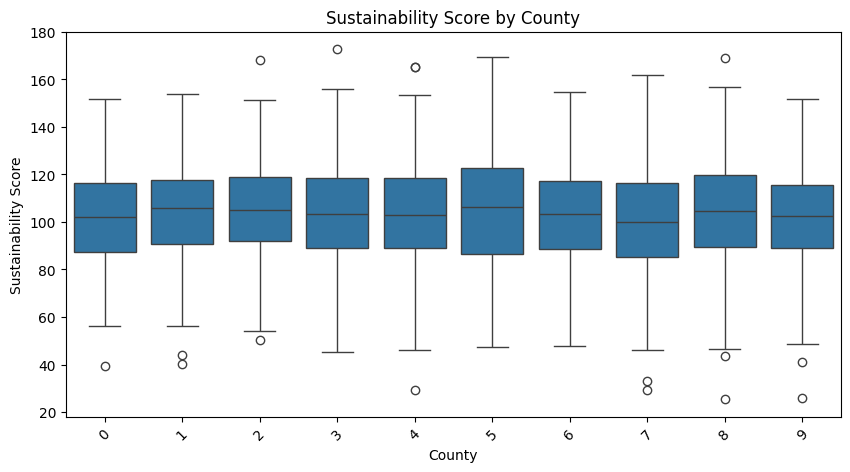

In [220]:
# Boxplot of revenue by county
plt.figure(figsize=(10, 5))
sns.boxplot(data=stats, x='County', y='sus_score')
plt.title('Sustainability Score by County')
plt.xlabel('County')
plt.ylabel('Sustainability Score')
plt.xticks(rotation=45)

plt.show()

## Question: Is mean fuel cost index different across all counties?

In [221]:
# H0: Mean fuel cost is the same across all counties.
# H1: At least one county has a significantly different mean fuel cost.
# Group by County
county_groups = [group['fc_index']for county, group in stats.groupby('County')]
#ANOVA test
f_stat, p_value = f_oneway(*county_groups)
#Print results
print('ANOVA Test: Fuel Cost Across Counties')
print('F-statistic:', f_stat)
print('P-value:', p_value)
if p_value < LoS:
    print('Reject H0: Significant result.')
else:
    print('Fail to reject H0.')

ANOVA Test: Fuel Cost Across Counties
F-statistic: 0.6509401774082815
P-value: 0.753830423469051
Fail to reject H0.


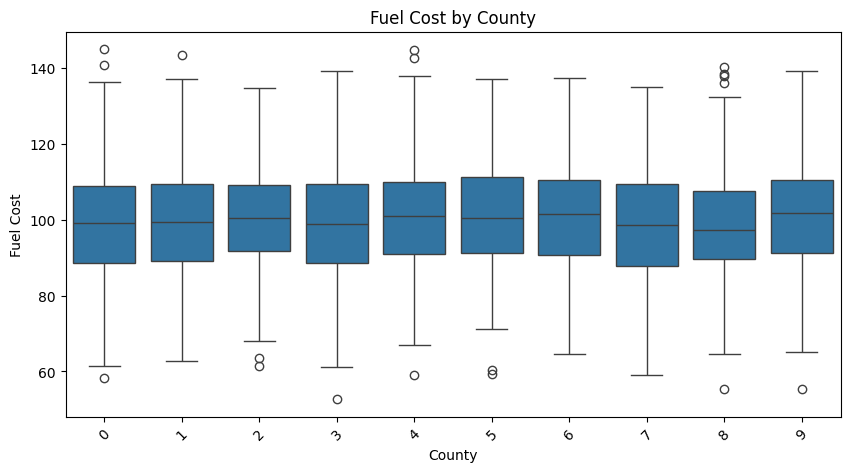

In [222]:
# Boxplot of revenue by county
plt.figure(figsize=(10, 5))
sns.boxplot(data=stats, x='County', y='fc_index')
plt.title('Fuel Cost by County')
plt.xlabel('County')
plt.ylabel('Fuel Cost')
plt.xticks(rotation=45)

plt.show()

## Question: Is mean revenue different across all counties?

In [102]:
# H0: Mean revenue is the same across all counties.
# H1: At least one county has a significantly different mean revenue.

county_groups = [group['par_eur']for county, group in stats.groupby('County')]
f_stat, p_value = f_oneway(*county_groups)
print('ANOVA Test: Revenue Across Counties')
print('F-statistic:', f_stat)
print('P-value:', p_value)
if p_value < LoS:
    print('Reject H0: Significant result.')
else:
    print('Fail to reject H0.')

ANOVA Test: Revenue Across Counties
F-statistic: 0.4718584235384168
P-value: 0.8942252796425437
Fail to reject H0.


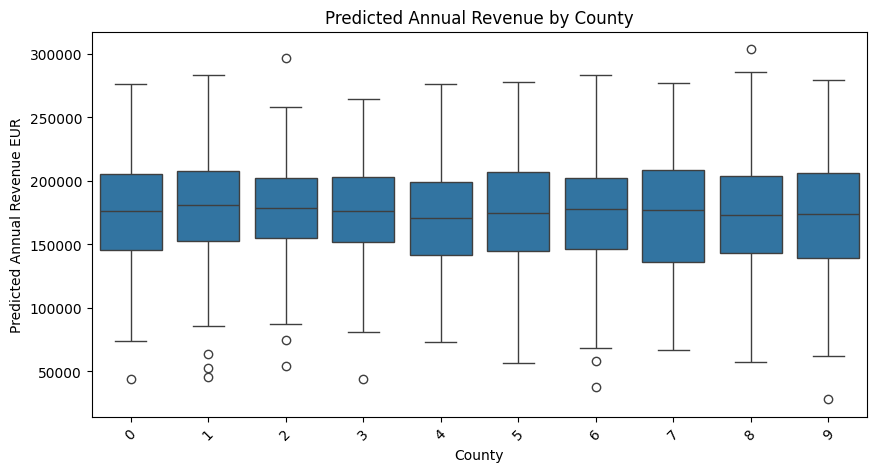

In [103]:
# Boxplot of revenue by county
plt.figure(figsize=(10, 5))

sns.boxplot(data=stats, x='County', y='par_eur')

plt.title('Predicted Annual Revenue by County')
plt.xlabel('County')
plt.ylabel('Predicted Annual Revenue EUR')
plt.xticks(rotation=45)

plt.show()

## Test 3: Pearson Correlation Test

## Question: Is there a significant relationship between sustainability score and revenue?

In [78]:
# H0: There is no significant relationship between average sustainability score and revenue.
# H1: There is a significant relationship between average sustainability score and revenue.
# Correlation test
corr, p_value = pearsonr(stats['sus_score'],stats['par_eur'])
# Print results
print('Pearson Correlation Test: Sustainability Score and Revenue')
print('Correlation coefficient:', corr)
print('P-value:', p_value)
# Set parameter for interpretation
if p_value < LoS:
    print('Reject H0: Significant result.')
else:
    print('Fail to reject H0.')

Pearson Correlation Test: Sustainability Score and Revenue
Correlation coefficient: 0.7837799306954643
P-value: 0.0
Reject H0: Significant result.


## Question: Is there a significant relationship between fisher income and revenue?

In [105]:
# H0: There is no significant relationship between average fisher income and revenue.
# H1: There is a significant relationship between average fisher income and revenue.
# Correlation test
corr, p_value = pearsonr(stats['afi_eur'],stats['par_eur'])
# Print results
print('Pearson Correlation Test: Fisher Income and Revenue')
print('Correlation coefficient:', corr)
print('P-value:', p_value)
# Set parameter for interpretation
if p_value < LoS:
    print('Reject H0: Significant result.')
else:
    print('Fail to reject H0.')

Pearson Correlation Test: Fisher Income and Revenue
Correlation coefficient: 0.9183300808833794
P-value: 0.0
Reject H0: Significant result.


# 5. Correlation Analysis and Linear Regression

### Correlation analysis with annual revenue

In [331]:
# Correlation of columns with target variable 'par_eur'
revenue_corr = stats[variables].corr()['par_eur'].sort_values(ascending=False)

revenue_corr

par_eur       1.000000
afi_eur       0.918330
fs_index      0.803643
sus_score     0.783780
wq_score      0.344210
pa_score      0.211616
ai_eur        0.181247
ves_type      0.014463
ifr_percen   -0.022664
County       -0.025847
fc_index     -0.043771
ed_level     -0.381124
wr_index     -0.383581
Name: par_eur, dtype: float64

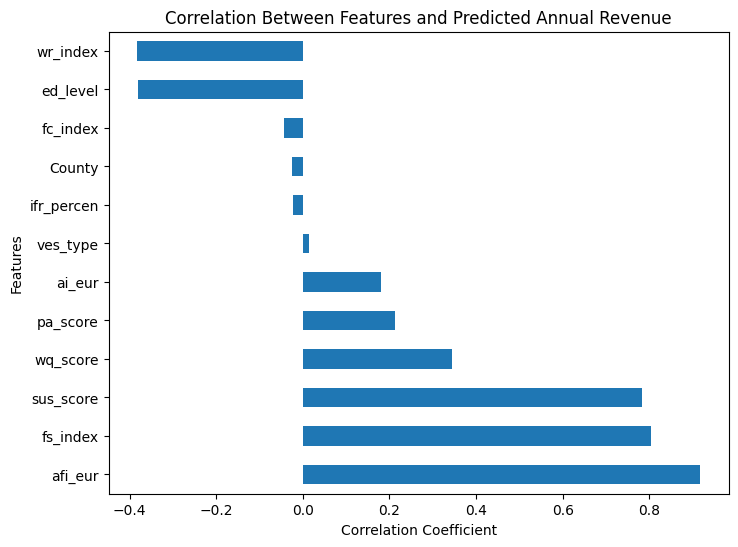

In [332]:
# Correlation bar chart
plt.figure(figsize=(8, 6))
revenue_corr.drop('par_eur').plot(kind='barh')
plt.title('Correlation Between Features and Predicted Annual Revenue')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')

plt.show()

### Correlation analysis with Export Demand Level

In [103]:
# Correlation of columns with target variable 'ed_level'
ed_corr = stats[variables].corr()['ed_level'].sort_values(ascending=False)

ed_corr

ed_level      1.000000
wr_index      0.227688
ifr_percen    0.126975
County        0.040778
fc_index      0.012411
ves_type      0.004754
ai_eur       -0.149851
pa_score     -0.185559
wq_score     -0.211659
fs_index     -0.234585
sus_score    -0.332937
afi_eur      -0.343593
par_eur      -0.381124
Name: ed_level, dtype: float64

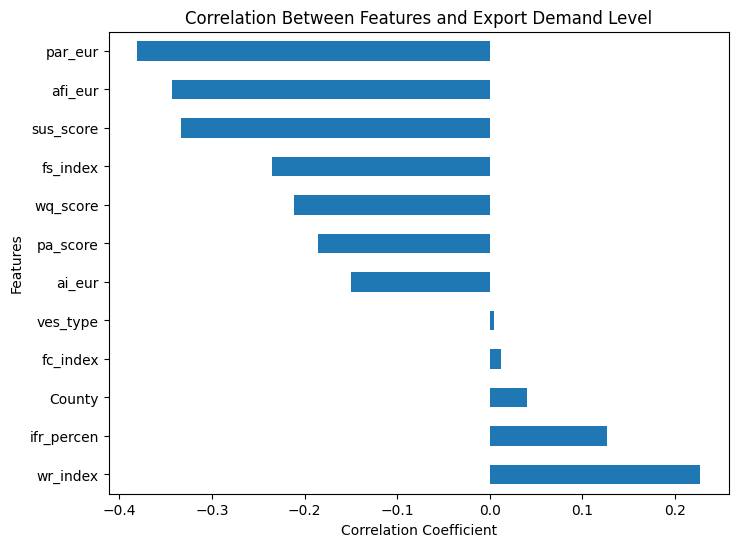

In [105]:
# Correlation bar chart
plt.figure(figsize=(8, 6))
ed_corr.drop('ed_level').plot(kind='barh')
plt.title('Correlation Between Features and Export Demand Level')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')

plt.show()

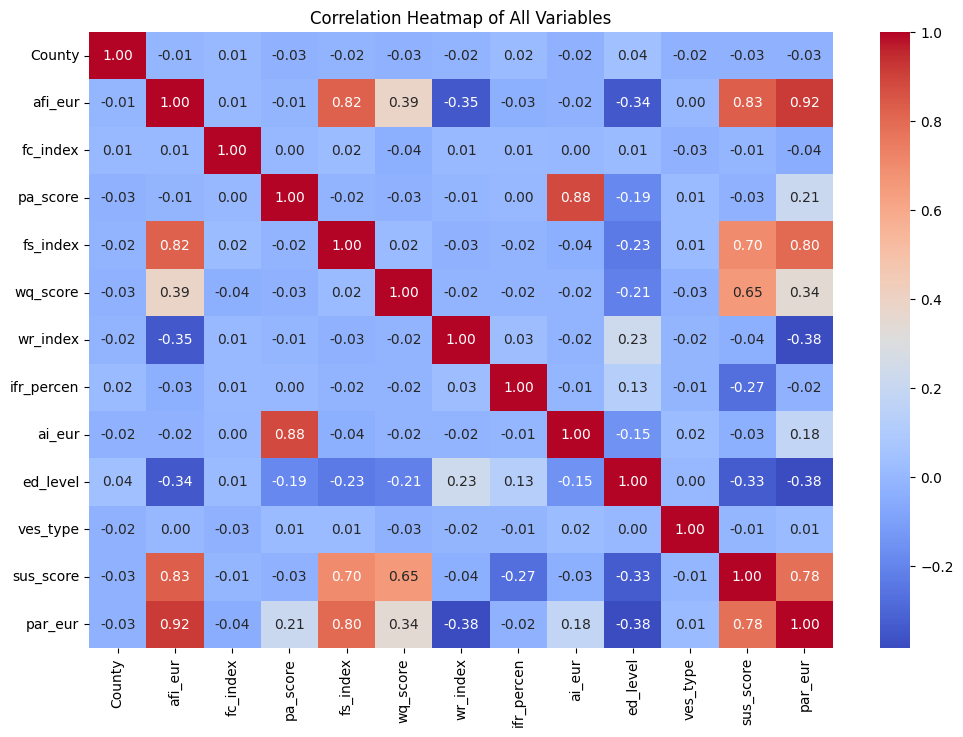

In [102]:
#Correlation heatmap for all variables
plt.figure(figsize=(12, 8))

sns.heatmap(stats[variables].corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title('Correlation Heatmap of All Variables')

plt.show()

### Linear Regression

In [79]:
# Select independent and dependent variables for linear regression
X = stats.drop(columns=['par_eur'])
y = stats['par_eur']

In [80]:
# Linear regression
lr_model = LinearRegression()
lr_model.fit(X, y)
y_pred = lr_model.predict(X)
r2 = r2_score(y, y_pred)
mae = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
print('Linear Regression Results')
print('R2 Score:', r2)
print('MAE:', mae)
print('RMSE:', rmse)

Linear Regression Results
R2 Score: 0.941738167740221
MAE: 8393.634367339699
RMSE: 10540.634758755177


In [81]:
# Coefficients and intercept
coefficients = pd.DataFrame({'Feature': X.columns,'Coefficient': lr_model.coef_})
intercept = lr_model.intercept_
print('Linear Regression Coefficients:')
print(coefficients)
print('\nIntercept:')
print(intercept)

Linear Regression Coefficients:
       Feature   Coefficient
0       County    -38.234879
1      afi_eur      0.811819
2     fc_index   -140.815704
3     pa_score   4636.814345
4     fs_index  10762.361653
5     wq_score   3732.055400
6     wr_index  -6442.976540
7   ifr_percen   1211.681850
8       ai_eur      0.041348
9     ed_level    -95.572078
10    ves_type    128.210384
11   sus_score    380.193754

Intercept:
-11131.292446582083


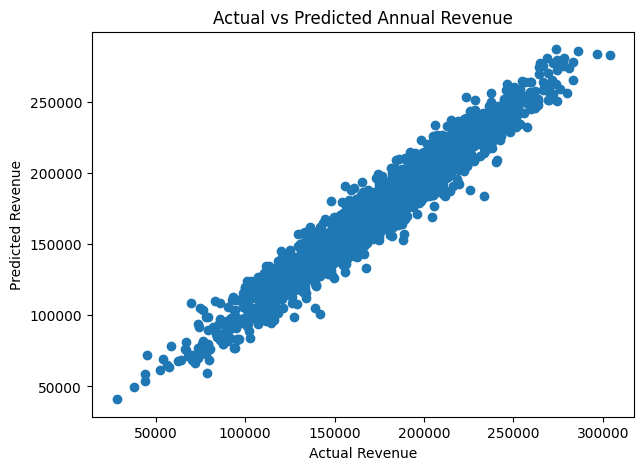

In [110]:
# Actual vs predicted revenue
plt.figure(figsize=(7, 5))
plt.scatter(y, y_pred)
plt.xlabel('Actual Revenue')
plt.ylabel('Predicted Revenue')
plt.title('Actual vs Predicted Annual Revenue')

plt.show()

# Regression task before feature selection

In [167]:
# Select features (independent variables) and target (dependent variable)
X = data.drop(columns=['par_eur'])  # Exclude 'par_eur'
y = data['par_eur']  # Target variable: 'par_eur'

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [168]:
# Models
models = {
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(n_estimators = 100, random_state = 42)
}

In [71]:
# Store results
results = []

# Train and evaluate models
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Append results to the list
    results.append([name, mae, mse, rmse, r2])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
print(results_df)

           Model           MAE           MSE          RMSE    R2 Score
0  Decision Tree  14756.086740  3.480054e+08  18654.902527    0.801198
1  Random Forest   9676.901567  1.505831e+08  12271.231722    0.913978


# Classification task before feature selection

In [73]:
# Check data
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,81077.05,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,1.0,1,99.44,201495.28
1,0,76078.84,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,0.0,4,115.02,202484.46
2,1,50576.94,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,2.0,1,61.75,107997.00
3,3,73236.59,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,0.0,3,115.48,188797.98
5,1,81472.19,86.89,7.72,6.41,5.69,1.00,1.78,143748.45,1.0,1,102.84,208188.97


In [74]:
# Define features and target variable
X = data.drop(columns=['par_eur', 'ed_level'])  
y = data['ed_level']  

In [75]:
# Show count of each class in the target variable
class_counts = y.value_counts()
print("Count of each class in 'ed_level'")
print(class_counts)

Count of each class in 'ed_level'
ed_level
0.0    863
2.0    496
1.0    466
Name: count, dtype: int64


In [76]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [129]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [78]:
# Train and evaluate ML model classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [79]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.715068   0.721693  0.715068  0.714599
1           Decision Tree  0.830137   0.831959  0.830137  0.830543
2           Random Forest  0.868493   0.871492  0.868493  0.868678
3     Logistic Regression  0.791781   0.800483  0.791781  0.792713
4  Support Vector Machine  0.750685   0.762381  0.750685  0.750150


# Feature importance

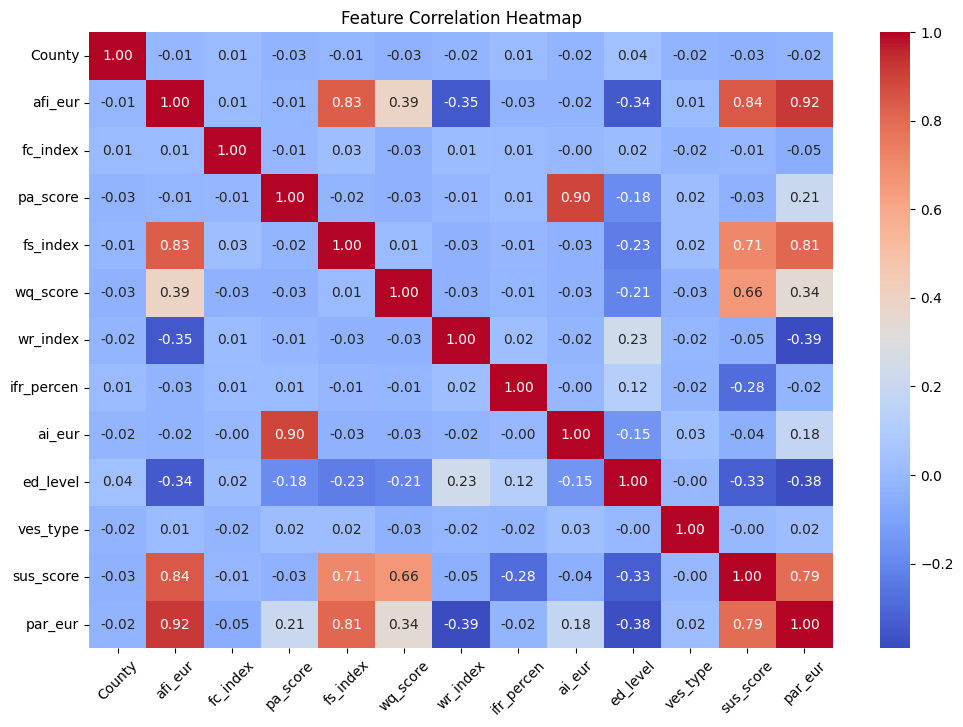

In [80]:
# Display heatmap for feature importance 
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

# Correlation matrix
corr = data.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt= ".2f")

plt.title("Feature Correlation Heatmap")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [81]:
#data = data.drop(columns = ["County", "ves_type", "ed_level"])

In [82]:
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,81077.05,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,1.0,1,99.44,201495.28
1,0,76078.84,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,0.0,4,115.02,202484.46
2,1,50576.94,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,2.0,1,61.75,107997.00
3,3,73236.59,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,0.0,3,115.48,188797.98
5,1,81472.19,86.89,7.72,6.41,5.69,1.00,1.78,143748.45,1.0,1,102.84,208188.97


# Regression task after dropping classification features

In [83]:
# Select features (independent variables) and target (dependent variable)
X = data.drop(columns=["County", "ves_type", "ed_level", "par_eur"])  # Exclude target variable and classification features
y = data['par_eur']  # Target variable

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [84]:
# Models
models = {
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(n_estimators = 100, random_state = 42)
}

In [85]:
# Store results
results = []

# Train and evaluate models
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Append results to the list
    results.append([name, mae, mse, rmse, r2])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
print(results_df)

           Model           MAE           MSE          RMSE    R2 Score
0  Decision Tree  15178.613205  3.568988e+08  18891.765087    0.796117
1  Random Forest  10049.453650  1.616768e+08  12715.220665    0.907640


# Classification task after feature selection

In [86]:
# Select features (independent variables) and target (dependent variable)
X = data.drop(columns=["County", "ves_type", "ed_level", "par_eur"])  # Exclude target variable and low correlation features
y = data['ed_level']  # Target variable

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [87]:
# Train and evaluate ML model classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [88]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.715068   0.721693  0.715068  0.714599
1           Decision Tree  0.838356   0.839053  0.838356  0.838574
2           Random Forest  0.890411   0.891277  0.890411  0.890558
3     Logistic Regression  0.778082   0.787391  0.778082  0.778639
4  Support Vector Machine  0.758904   0.767067  0.758904  0.758692


# Dicretization

# Discretization
### Fuel Cost Index = Index (base 100 scale) 
A base 100 index means
●	100 represents the reference or average fuel cost level.
●	Values above 100 indicate higher-than-average fuel costs.
●	Values below 100 indicate lower-than-average fuel costs.

### Sustainability_Score
Index score
●	Min: approx. 25
●	Mean: approx. 103
●	Typical range (most values): 80 to 130
●	High values: 140 - 170 (very strong sustainability)

### Illegal_Fishing_Rate_%


In [106]:
from sklearn.preprocessing import KBinsDiscretizer

In [107]:
# Select dependent and target variables
y = data['ed_level'] # Select only classification target variable
X = data.drop(columns = ['ed_level', 'par_eur']) # Drop both target variables

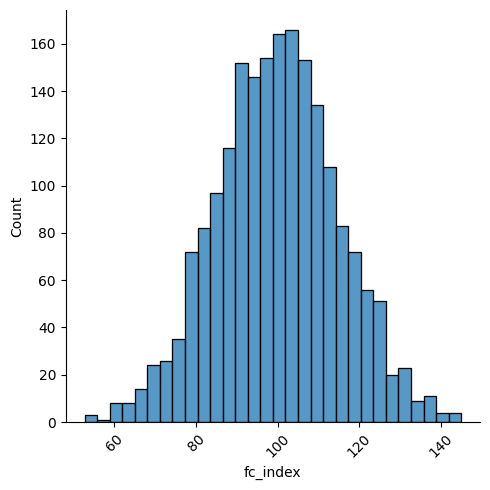

In [108]:
# fc_index distribution
sns.displot(x = X['fc_index'])
plt.xticks(rotation = 45)
plt.tight_layout()

In [109]:
#equal_width_discretizer 
equal_width_discretizer = KBinsDiscretizer(n_bins = 50,
                                          encode = "ordinal",
                                          strategy = "uniform", 
                                          subsample = None)
equal_width_discretizer.fit(X[['fc_index']])
X['equal_width_fc'] = equal_width_discretizer.transform(X[['fc_index']])

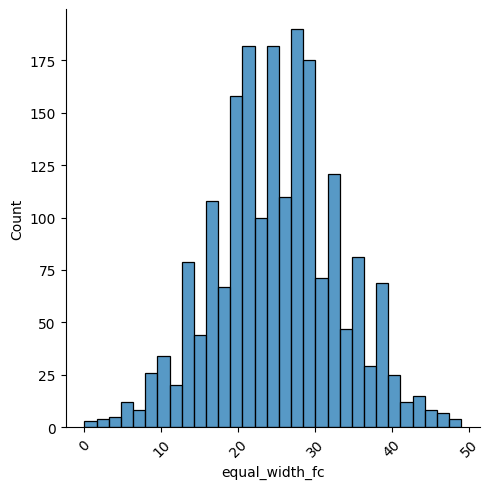

In [110]:
# Distribution after discretizer
sns.displot(x = X['equal_width_fc'])
plt.xticks(rotation = 45)
plt.tight_layout()

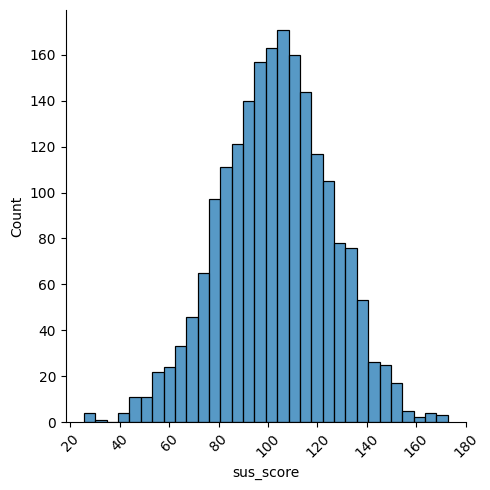

In [111]:
#sus_score distribution before discretizer
sns.displot(x = X['sus_score'])
plt.xticks(rotation = 45)
plt.tight_layout()

In [112]:
# equal_width_discretizer
equal_width_discretizer = KBinsDiscretizer(n_bins = 50,
                                          encode = "ordinal",
                                          strategy = "uniform", 
                                          subsample = None)
equal_width_discretizer.fit(X[['sus_score']])
X['equal_width_sus'] = equal_width_discretizer.transform(X[['sus_score']])

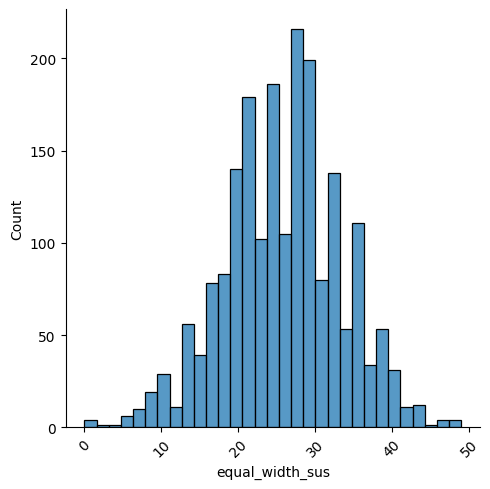

In [113]:
# sus_score distribution after discretizer
sns.displot(x = X['equal_width_sus'])
plt.xticks(rotation = 45)
plt.tight_layout()

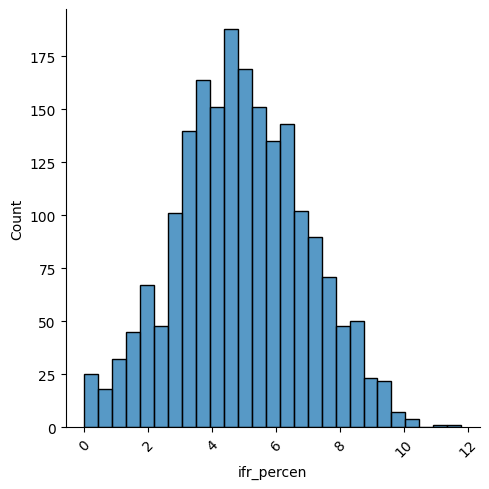

In [114]:
# ifr_percen distribution before discretizer
sns.displot(x = X['ifr_percen'])
plt.xticks(rotation = 45)
plt.tight_layout()

In [115]:
#equal_width_discretize
equal_width_discretizer = KBinsDiscretizer(n_bins = 50,
                                          encode = "ordinal",
                                          strategy = "uniform", 
                                          subsample = None)
equal_width_discretizer.fit(X[['ifr_percen']])
X['equal_width_ifr'] = equal_width_discretizer.transform(X[['ifr_percen']])

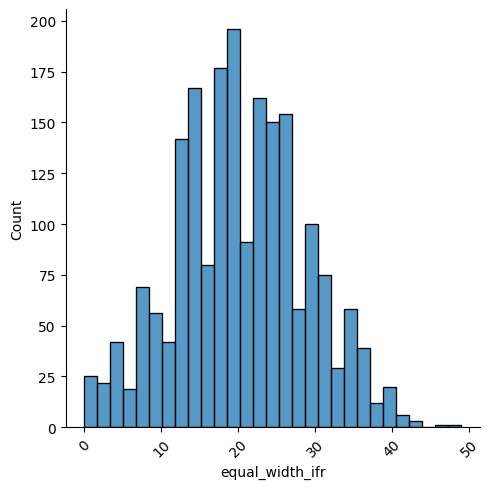

In [116]:
# ifr_percent distribution after discretizer
sns.displot(x = X['equal_width_ifr'])
plt.xticks(rotation = 45)
plt.tight_layout()

In [117]:
# equal_freq_discretizer 
equal_freq_discretizer = KBinsDiscretizer(n_bins = 50,
                                          encode = "ordinal",
                                          strategy = "quantile", 
                                          subsample = None)
equal_freq_discretizer.fit(X[['ifr_percen']])
X['equal_freq_ifr'] = equal_freq_discretizer.transform(X[['ifr_percen']])

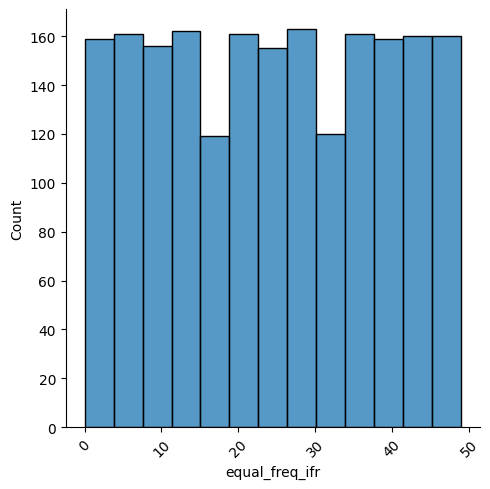

In [118]:
# ifr_percent distribution after discretizer
sns.displot(x = X['equal_freq_ifr'])
plt.xticks(rotation = 45)
plt.tight_layout()

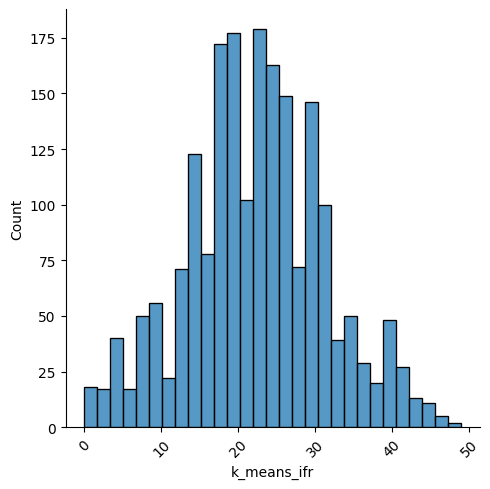

In [119]:
# k_means_discretizer
k_means_discretizer = KBinsDiscretizer(n_bins = 50,
                                          encode = "ordinal",
                                          strategy = "kmeans", 
                                          subsample = None)
k_means_discretizer.fit(X[['ifr_percen']])
X['k_means_ifr'] = k_means_discretizer.transform(X[['ifr_percen']])

sns.displot(x = X['k_means_ifr'])
plt.xticks(rotation = 45)
plt.tight_layout()

In [120]:
# ifr_percent statistical information for custom discretizer
data['ifr_percen'].describe()

count    1996.000000
mean        4.918442
std         2.006820
min         0.000000
25%         3.567500
50%         4.850000
75%         6.330000
max        11.790000
Name: ifr_percen, dtype: float64

In [121]:
# Define values for custom discretization
def custom_discretization(value):
    if value < 3:
        return 0
    elif value >= 3 and value < 7:
        return 1
    else:
        return 2

In [122]:
# Apply custom discretization
X['custom_bins']=X['ifr_percen'].apply(custom_discretization)

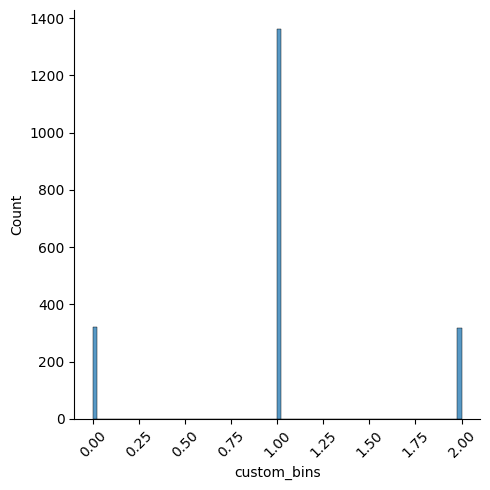

In [123]:
# Plot distribution after custom discretization
sns.displot(x=X['custom_bins'])
plt.xticks(rotation=45)
plt.tight_layout()

In [125]:
# Check changes made and discretizations
X.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ves_type,sus_score,equal_width_fc,equal_width_sus,equal_width_ifr,equal_freq_ifr,k_means_ifr,custom_bins
0,8,81077.05,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,1,99.44,20.0,25.0,17.0,17.0,19.0,1
1,0,76078.84,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,4,115.02,25.0,30.0,17.0,17.0,19.0,1
2,1,50576.94,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,1,61.75,21.0,12.0,13.0,8.0,14.0,1
3,3,73236.59,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,3,115.48,30.0,30.0,23.0,31.0,25.0,1
5,1,81472.19,86.89,7.72,6.41,5.69,1.00,1.78,143748.45,1,102.84,18.0,26.0,7.0,3.0,8.0,0


# Classification task after discretization

In [126]:
from sklearn.tree import DecisionTreeRegressor 
# Select features (independent variables) and target (dependent variable)
X_data = X.drop(columns = ['custom_bins', 'equal_width_ifr', 'k_means_ifr'])
y = data['ed_level']  # Target variable

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X_data, y, test_size = 0.2, random_state = 42)

In [127]:
# Independent variables
X_data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ves_type,sus_score,equal_width_fc,equal_width_sus,equal_freq_ifr
0,8,81077.05,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,1,99.44,20.0,25.0,17.0
1,0,76078.84,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,4,115.02,25.0,30.0,17.0
2,1,50576.94,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,1,61.75,21.0,12.0,8.0
3,3,73236.59,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,3,115.48,30.0,30.0,31.0
5,1,81472.19,86.89,7.72,6.41,5.69,1.00,1.78,143748.45,1,102.84,18.0,26.0,3.0


In [130]:
# Train and evaluate ML model classifiers 
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [131]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision  Recall  F1 Score
0     k-Nearest Neighbors    0.7125   0.713517  0.7125  0.712190
1           Decision Tree    0.8175   0.818505  0.8175  0.817668
2           Random Forest    0.8900   0.893031  0.8900  0.889930
3     Logistic Regression    0.8050   0.805714  0.8050  0.805027
4  Support Vector Machine    0.7525   0.755513  0.7525  0.752892


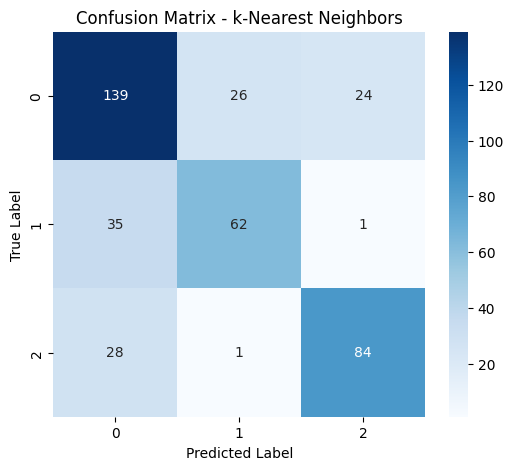

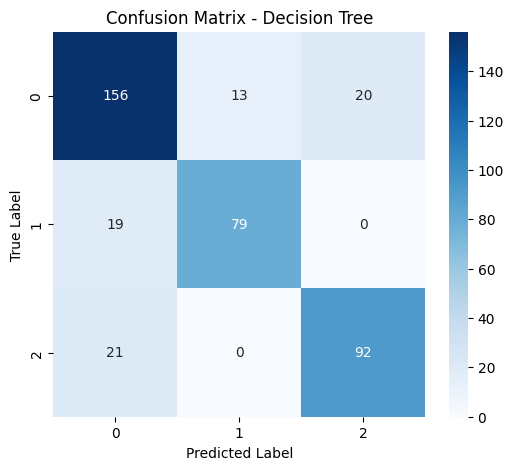

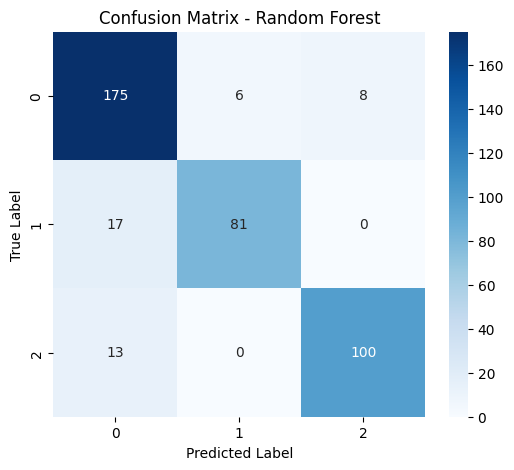

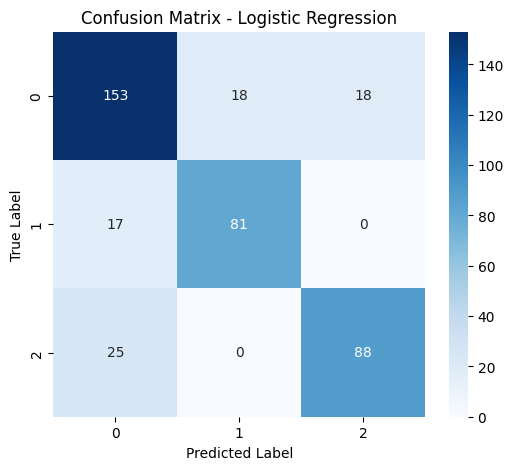

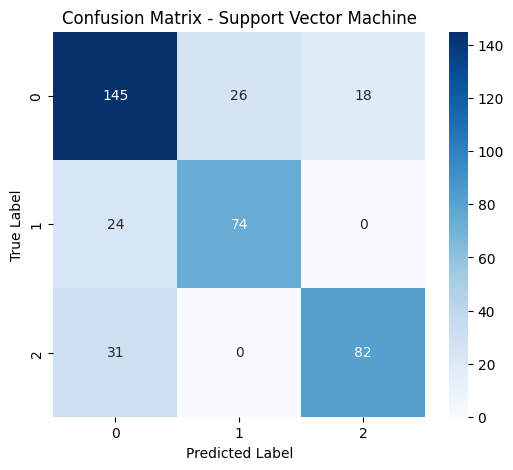

In [132]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix for each classifier
for name, classifier in classifiers.items():
    
    # Train model
    classifier.fit(X_train, y_train)
    
    # Predict test data
    y_pred = classifier.predict(X_test)
    
    # Compute confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    
    # Plot confusion matrix
    plt.figure(figsize=(6,5))
    
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
    
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    
    plt.show()

# Scaling Independent Variables

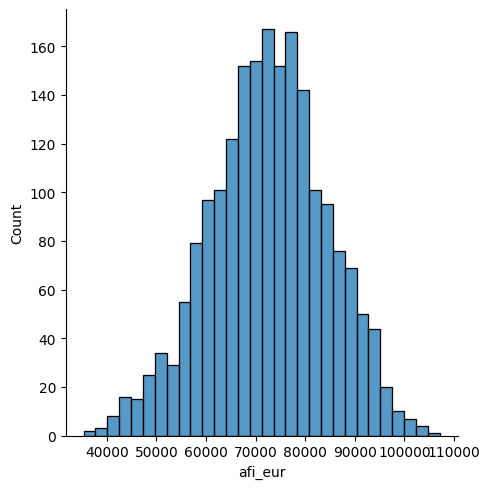

In [531]:
# afi_eur distribution
sns.displot(data, x='afi_eur');

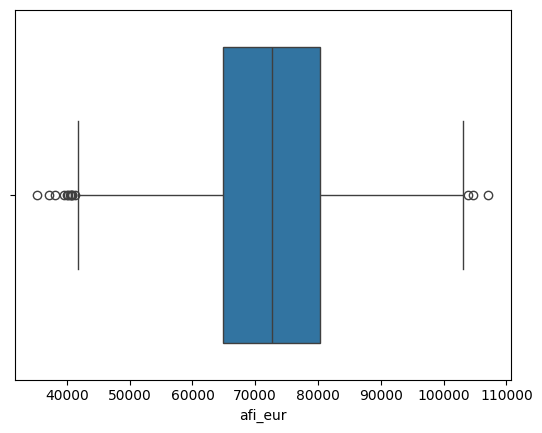

In [532]:
# afi_eur outliers
sns.boxplot(data, x='afi_eur');

In [533]:
# Chosen method Robust Scaler
scaler = RobustScaler()
data[['afi_eur']] = scaler.fit_transform(data[['afi_eur']])

In [534]:
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,0.540898,91.19,6.95,5.10,7.10,1.23,4.12,108112.88,1.0,1,99.44,201495.28
1,0,0.218485,99.09,7.51,8.20,6.16,5.38,4.06,112746.74,0.0,4,115.02,202484.46
2,1,-1.426534,91.93,7.59,3.82,4.04,4.71,3.07,132088.49,2.0,1,61.75,107997.00
3,3,0.035143,109.53,6.29,7.02,7.60,5.99,5.56,109732.87,0.0,3,115.48,188797.98
5,1,0.566387,86.89,7.72,6.41,5.69,1.00,1.78,143748.45,1.0,1,102.84,208188.97


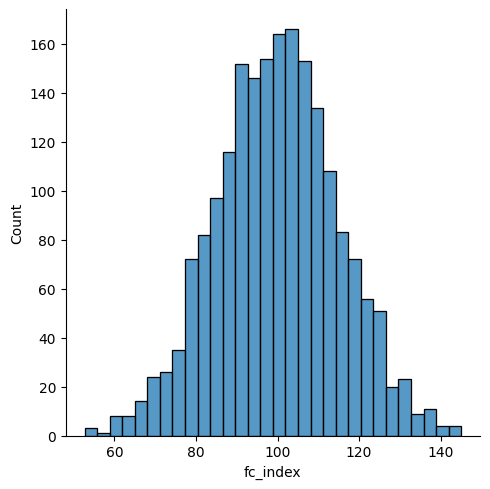

In [535]:
# fc_index distribution
sns.displot(data, x='fc_index');

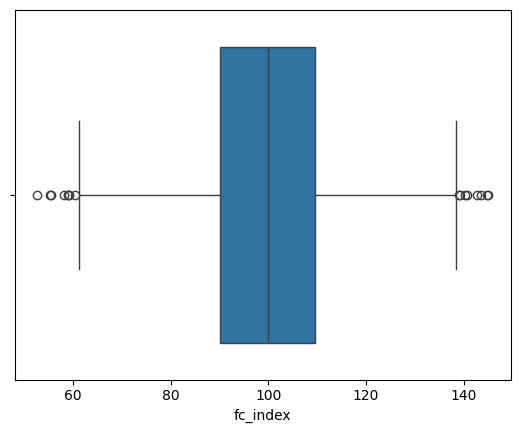

In [536]:
# fc_index outliers
sns.boxplot(data, x='fc_index');

In [537]:
# Chosen methos Robust Scaler
scaler = RobustScaler()
data[['fc_index']] = scaler.fit_transform(data[['fc_index']])

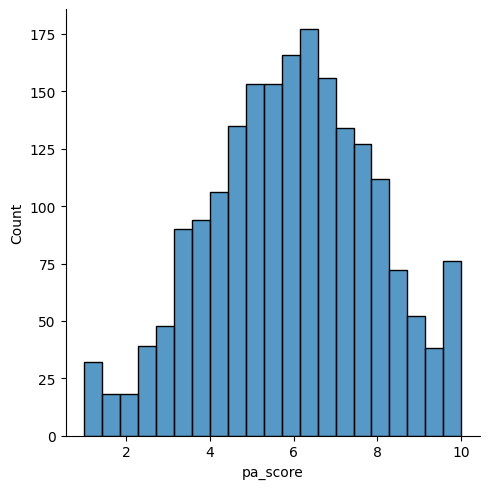

In [538]:
# pa_score distribution
sns.displot(data, x='pa_score');

<Axes: xlabel='pa_score'>

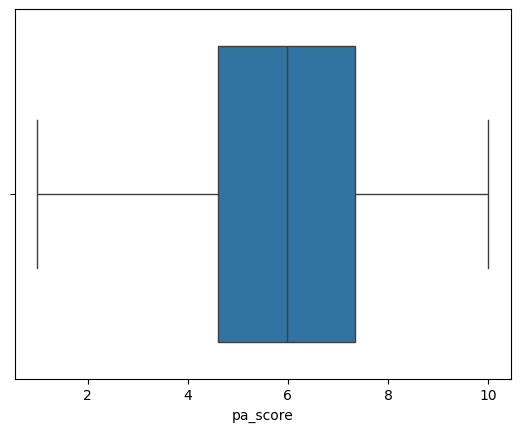

In [539]:
# pa_score outliers
sns.boxplot(data=data, x='pa_score')

In [540]:
# Chosen method Standard Scaler
data['pa_score']=preproc.StandardScaler().fit_transform(data[['pa_score']])

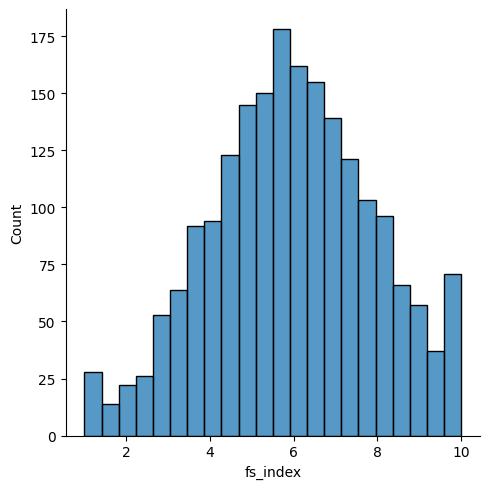

In [541]:
# fs_index distribution
sns.displot(data, x='fs_index');

<Axes: xlabel='fs_index'>

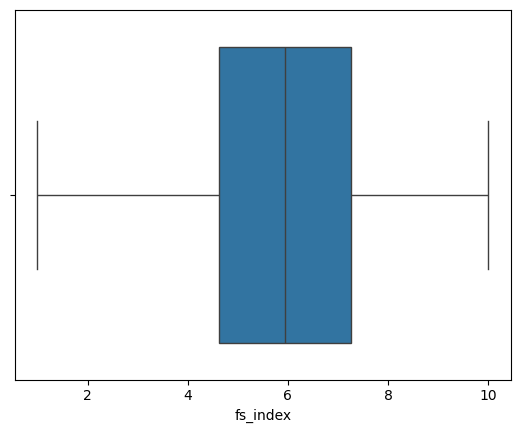

In [542]:
# fs_index outliers
sns.boxplot(data=data, x='fs_index')

In [543]:
# Chosen method Standard Scaler
data['fs_index']=preproc.StandardScaler().fit_transform(data[['fs_index']])

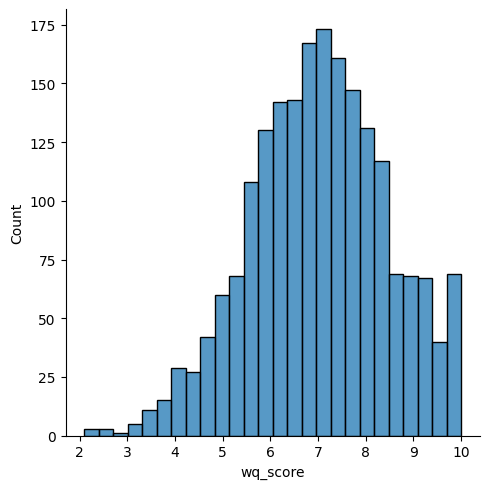

In [544]:
# wq_score distribution
sns.displot(data, x='wq_score');

<Axes: xlabel='wq_score'>

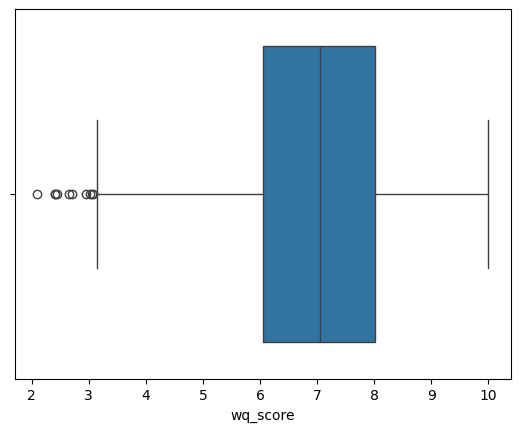

In [545]:
# wq_score outliers
sns.boxplot(data=data, x='wq_score')

In [546]:
# Chosen method Robust Scaler
scaler = RobustScaler()
data[['wq_score']] = scaler.fit_transform(data[['wq_score']])

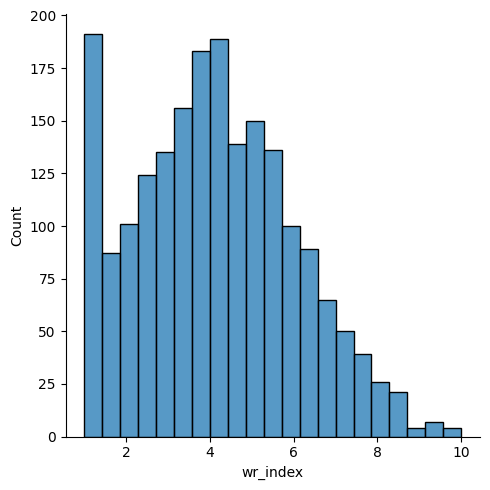

In [547]:
# wr_index distribution
sns.displot(data, x='wr_index');

<Axes: xlabel='wr_index'>

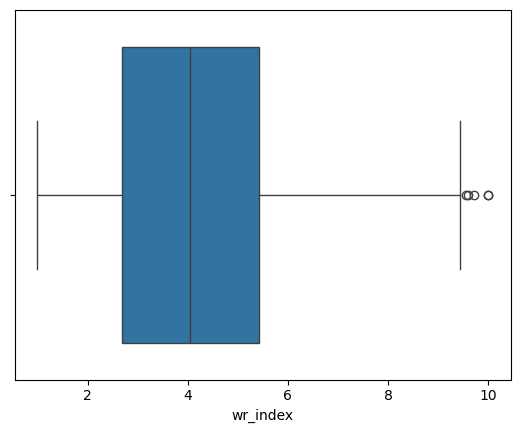

In [548]:
# wr_index outliers
sns.boxplot(data=data, x='wr_index')

In [549]:
# Chosen method Robust Scaler
scaler = RobustScaler()
data[['wr_index']] = scaler.fit_transform(data[['wr_index']])

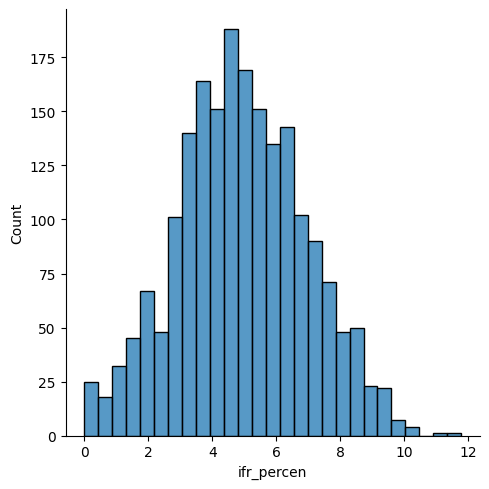

In [550]:
#ifr_percen distribution
sns.displot(data, x='ifr_percen');

<Axes: xlabel='ifr_percen'>

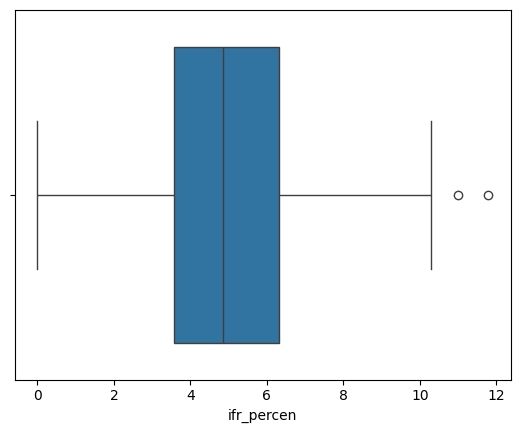

In [551]:
#ifr_percen outliers
sns.boxplot(data=data, x='ifr_percen')

In [552]:
# Chosen method Standard Scaler
scaler = RobustScaler()
data[['ifr_percen']] = scaler.fit_transform(data[['ifr_percen']])

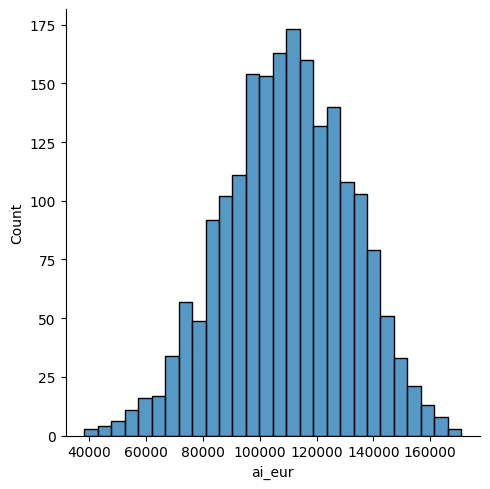

In [553]:
# ai_eur distribution
sns.displot(data, x='ai_eur');

<Axes: xlabel='ai_eur'>

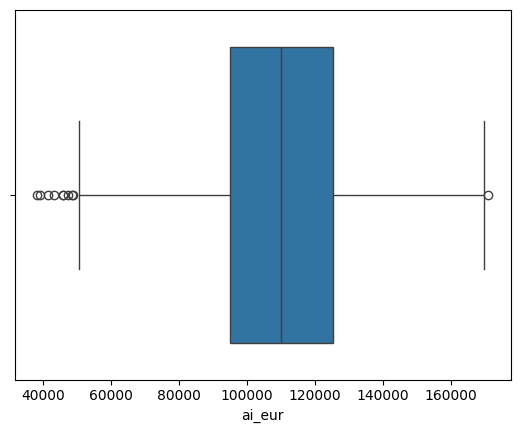

In [554]:
# ai_eur outliers
sns.boxplot(data=data, x='ai_eur')

In [555]:
# Chosen method Robust Scaler
scaler = RobustScaler()
data[['ai_eur']] = scaler.fit_transform(data[['ai_eur']])

In [556]:
# Check changes made 
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,0.540898,-0.444359,0.503282,-0.436984,0.025445,-1.028259,-0.264253,-0.063615,1.0,1,99.44,201495.28
1,0,0.218485,-0.040629,0.785662,1.152712,-0.452926,0.484959,-0.285973,0.089532,0.0,4,115.02,202484.46
2,1,-1.426534,-0.406541,0.826002,-1.093374,-1.531807,0.240656,-0.644344,0.728768,2.0,1,61.75,107997.00
3,3,0.035143,0.492909,0.170477,0.547602,0.279898,0.707384,0.257014,-0.010075,0.0,3,115.48,188797.98
5,1,0.566387,-0.664111,0.891555,0.234791,-0.692112,-1.112124,-1.111312,1.114125,1.0,1,102.84,208188.97


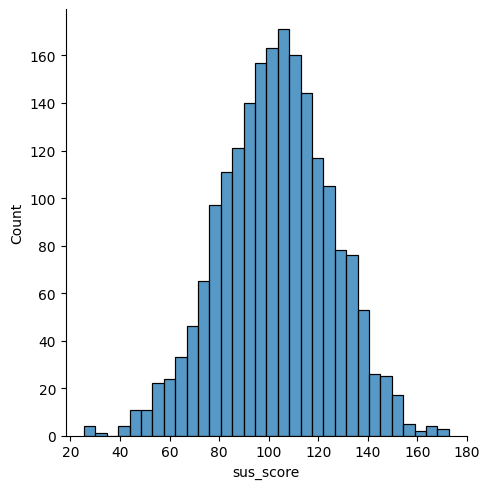

In [557]:
# sus_score distribution
sns.displot(data, x='sus_score');

<Axes: xlabel='sus_score'>

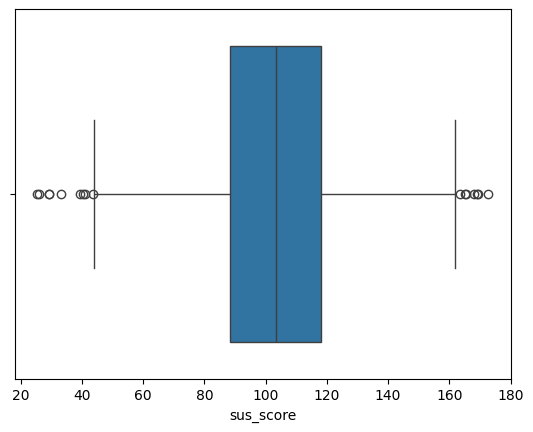

In [558]:
# sus_score outliers
sns.boxplot(data=data, x='sus_score')

In [559]:
# Chosen method Robust Scaler
scaler = RobustScaler()
data[['sus_score']] = scaler.fit_transform(data[['sus_score']])

In [560]:
# Check all changes made
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,0.540898,-0.444359,0.503282,-0.436984,0.025445,-1.028259,-0.264253,-0.063615,1.0,1,-0.130120,201495.28
1,0,0.218485,-0.040629,0.785662,1.152712,-0.452926,0.484959,-0.285973,0.089532,0.0,4,0.395078,202484.46
2,1,-1.426534,-0.406541,0.826002,-1.093374,-1.531807,0.240656,-0.644344,0.728768,2.0,1,-1.400640,107997.00
3,3,0.035143,0.492909,0.170477,0.547602,0.279898,0.707384,0.257014,-0.010075,0.0,3,0.410585,188797.98
5,1,0.566387,-0.664111,0.891555,0.234791,-0.692112,-1.112124,-1.111312,1.114125,1.0,1,-0.015506,208188.97


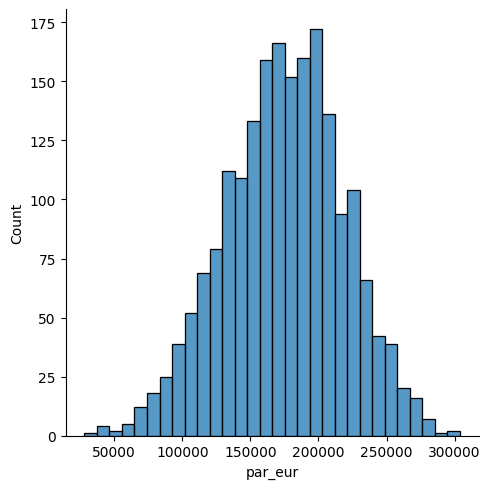

In [561]:
#par_eur distribution
sns.displot(data, x='par_eur');

<Axes: xlabel='par_eur'>

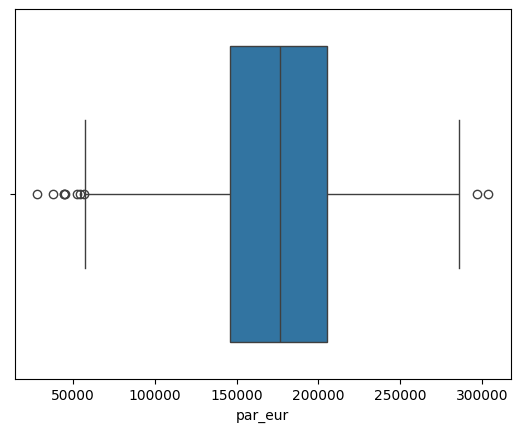

In [562]:
# par_eur outliers
sns.boxplot(data=data, x='par_eur')

In [563]:
#scaler = RobustScaler()
#data[['par_eur']] = scaler.fit_transform(data[['par_eur']])

In [564]:
# Check all changes
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,0.540898,-0.444359,0.503282,-0.436984,0.025445,-1.028259,-0.264253,-0.063615,1.0,1,-0.130120,201495.28
1,0,0.218485,-0.040629,0.785662,1.152712,-0.452926,0.484959,-0.285973,0.089532,0.0,4,0.395078,202484.46
2,1,-1.426534,-0.406541,0.826002,-1.093374,-1.531807,0.240656,-0.644344,0.728768,2.0,1,-1.400640,107997.00
3,3,0.035143,0.492909,0.170477,0.547602,0.279898,0.707384,0.257014,-0.010075,0.0,3,0.410585,188797.98
5,1,0.566387,-0.664111,0.891555,0.234791,-0.692112,-1.112124,-1.111312,1.114125,1.0,1,-0.015506,208188.97


In [565]:
# Check first 5 rows
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,0.540898,-0.444359,0.503282,-0.436984,0.025445,-1.028259,-0.264253,-0.063615,1.0,1,-0.130120,201495.28
1,0,0.218485,-0.040629,0.785662,1.152712,-0.452926,0.484959,-0.285973,0.089532,0.0,4,0.395078,202484.46
2,1,-1.426534,-0.406541,0.826002,-1.093374,-1.531807,0.240656,-0.644344,0.728768,2.0,1,-1.400640,107997.00
3,3,0.035143,0.492909,0.170477,0.547602,0.279898,0.707384,0.257014,-0.010075,0.0,3,0.410585,188797.98
5,1,0.566387,-0.664111,0.891555,0.234791,-0.692112,-1.112124,-1.111312,1.114125,1.0,1,-0.015506,208188.97


In [259]:
# Check null values
data.isnull().sum()

County        0
afi_eur       0
fc_index      0
pa_score      0
fs_index      0
wq_score      0
wr_index      0
ifr_percen    0
ai_eur        0
ed_level      0
ves_type      0
sus_score     0
par_eur       0
dtype: int64

# REGRESSION TASK
### Test model with scaled data
### Testing size 20%

In [260]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [261]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Select features (independent variables) and target (dependent variable)
X = data.drop(columns=['par_eur'])  # Exclude target variable
y = data['par_eur']  # Target variable

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [262]:
# Models
models = {
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(n_estimators = 100, random_state = 42)
}

In [263]:
# Store results
results = []

# Train and evaluate models
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Append results to the list
    results.append([name, mae, mse, rmse, r2])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
print(results_df)

           Model           MAE           MSE          RMSE    R2 Score
0  Decision Tree  14478.180450  3.392724e+08  18419.348826    0.832120
1  Random Forest  10071.642799  1.548132e+08  12442.397003    0.923395


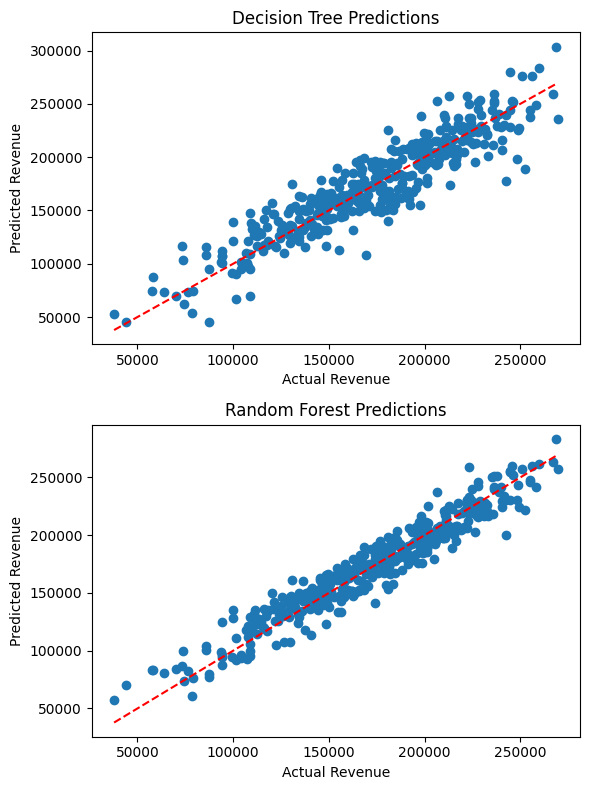

In [266]:
# Store predictions
predictions = {}

for name, model in models.items():   
    # Train model
    model.fit(X_train, y_train)   
    # Predict on test set
    y_pred = model.predict(X_test)    
    predictions[name] = y_pred

# Visualization
plt.figure(figsize=(6,8))
for i, (name, y_pred) in enumerate(predictions.items()):   
    plt.subplot(2, 1, i + 1)
    plt.scatter(y_test, y_pred)
    # Ideal prediction line
    plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],'r--')
    plt.title(f'{name} Predictions')
    plt.xlabel('Actual Revenue')
    plt.ylabel('Predicted Revenue')

plt.tight_layout()
plt.show()

### Testing size 30%

In [267]:
# Select features (independent variables) and target (dependent variable)
X = data.drop(columns=['par_eur'])  # Exclude target variable
y = data['par_eur']  # Target variable

# Split the data into training and testing sets (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [268]:
# Store results
results = []

# Train and evaluate models
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Append results to the list
    results.append([name, mae, mse, rmse, r2])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
print(results_df)

           Model           MAE           MSE          RMSE    R2 Score
0  Decision Tree  14462.035092  3.340941e+08  18278.241494    0.833834
1  Random Forest  10439.230066  1.712186e+08  13085.053454    0.914842


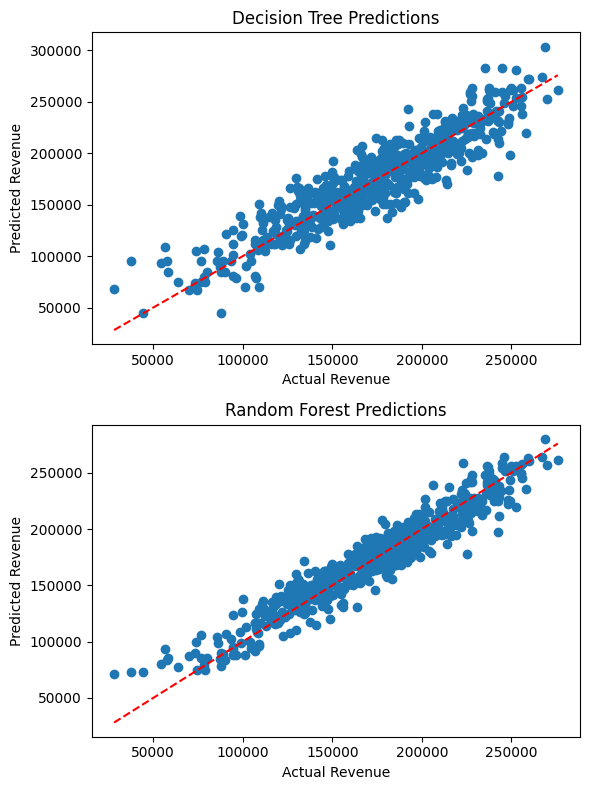

In [269]:
# Store predictions
predictions = {}

for name, model in models.items():   
    # Train model
    model.fit(X_train, y_train)   
    # Predict on test set
    y_pred = model.predict(X_test)    
    predictions[name] = y_pred

# Visualization
plt.figure(figsize=(6,8))
for i, (name, y_pred) in enumerate(predictions.items()):   
    plt.subplot(2, 1, i + 1)
    plt.scatter(y_test, y_pred)
    # Ideal prediction line
    plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],'r--')
    plt.title(f'{name} Predictions')
    plt.xlabel('Actual Revenue')
    plt.ylabel('Predicted Revenue')

plt.tight_layout()
plt.show()

# Classification task
### Test model with scaled data
### Testing size 20%

In [270]:
# Define features and target variable
X = data.drop(columns=['par_eur', 'ed_level'])  # Exclude target variable
y = data['ed_level']  # Target variable
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [271]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [272]:
# Train and evaluate ML model classifiers 
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [273]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision  Recall  F1 Score
0     k-Nearest Neighbors    0.7775   0.788233  0.7775  0.776820
1           Decision Tree    0.7900   0.792809  0.7900  0.790137
2           Random Forest    0.9000   0.902247  0.9000  0.899651
3     Logistic Regression    0.9675   0.967645  0.9675  0.967516
4  Support Vector Machine    0.9775   0.977603  0.9775  0.977495


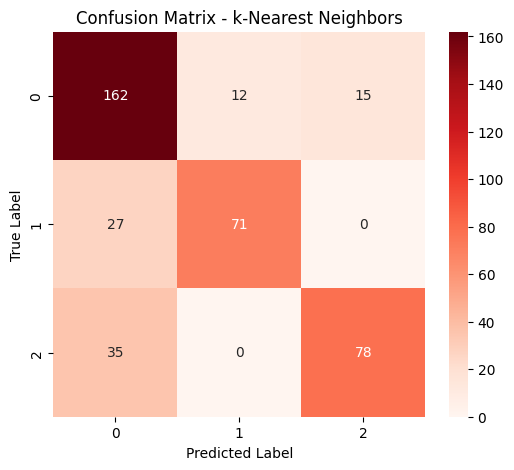

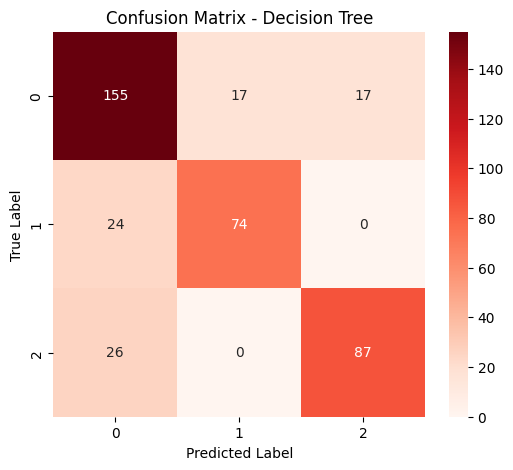

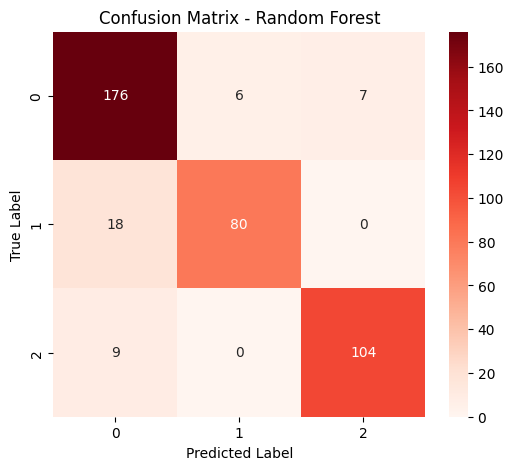

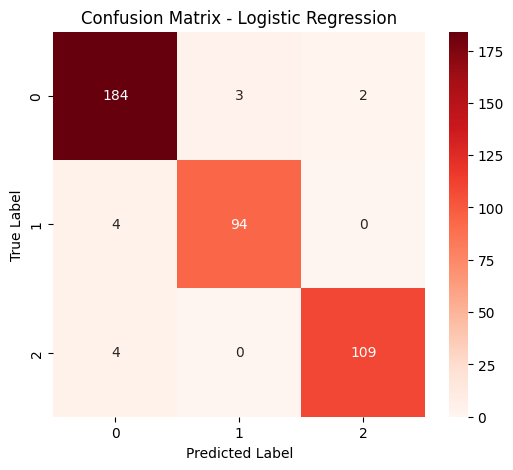

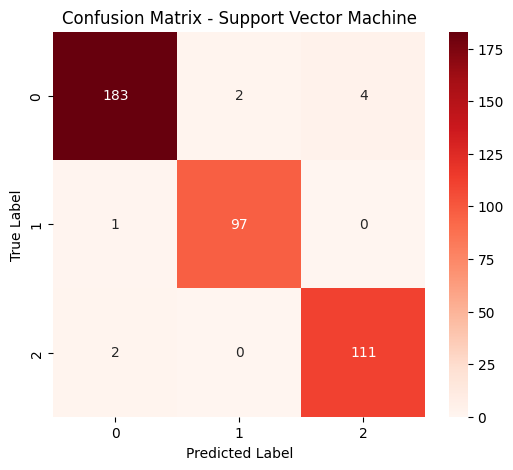

In [274]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Plot confusion matrix for each classifier
for name, classifier in classifiers.items():

    # Train the classifier
    classifier.fit(X_train, y_train)

    # Predict on the test set
    y_pred = classifier.predict(X_test)

    # Create confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix
    plt.figure(figsize=(6,5))

    sns.heatmap(cm,annot=True,fmt='d',cmap='Reds')

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    plt.show()

### Testing size 30%

In [275]:
# Define features and target variable
X = data.drop(columns=['par_eur', 'ed_level'])  # Exclude target variable
y = data['ed_level']  # Target variable
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [276]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [277]:
# Train and evaluate ML model classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [278]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.782972   0.791395  0.782972  0.782513
1           Decision Tree  0.781302   0.781018  0.781302  0.781058
2           Random Forest  0.888147   0.889458  0.888147  0.887903
3     Logistic Regression  0.959933   0.959873  0.959933  0.959882
4  Support Vector Machine  0.963272   0.963272  0.963272  0.963272


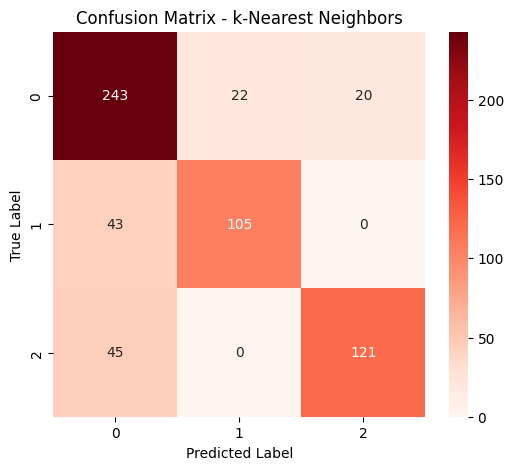

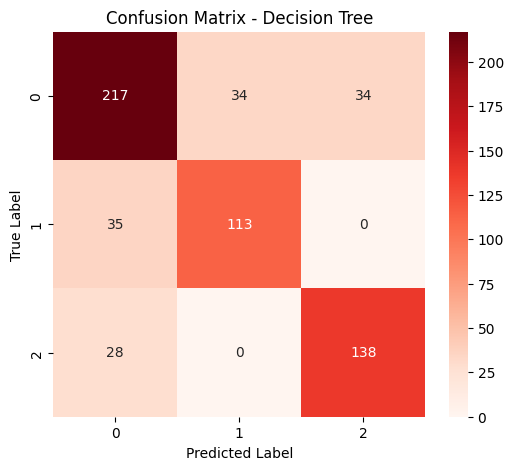

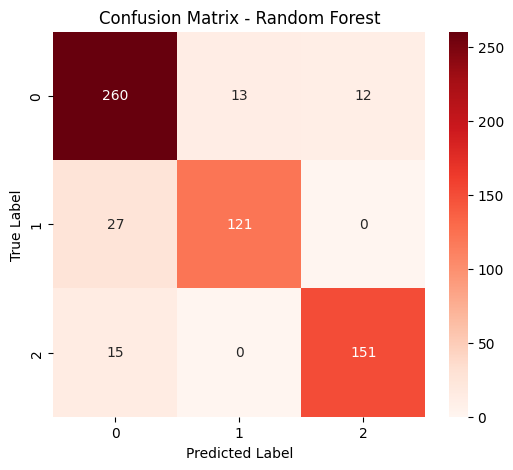

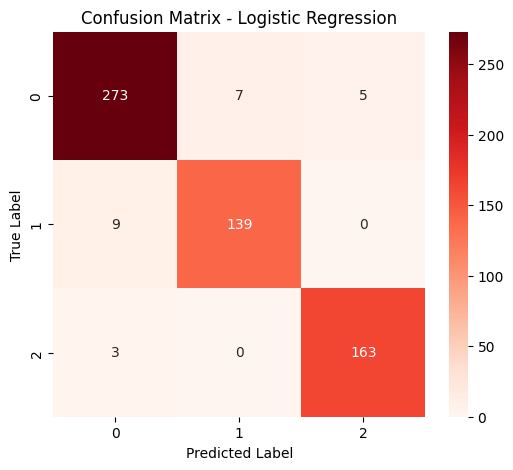

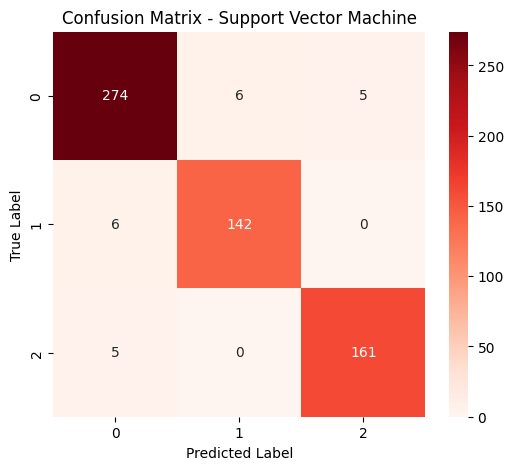

In [279]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Plot confusion matrix for each classifier
for name, classifier in classifiers.items():

    # Train the classifier
    classifier.fit(X_train, y_train)

    # Predict on the test set
    y_pred = classifier.predict(X_test)

    # Create confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix
    plt.figure(figsize=(6,5))

    sns.heatmap(cm,annot=True,fmt='d',cmap='Reds')

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    plt.show()

In [341]:
# Check 5 first rows
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,0.540898,-0.444359,0.503282,-0.436984,0.025445,-1.028259,-0.264253,-0.063615,1.0,1,-0.130120,201495.28
1,0,0.218485,-0.040629,0.785662,1.152712,-0.452926,0.484959,-0.285973,0.089532,0.0,4,0.395078,202484.46
2,1,-1.426534,-0.406541,0.826002,-1.093374,-1.531807,0.240656,-0.644344,0.728768,2.0,1,-1.400640,107997.00
3,3,0.035143,0.492909,0.170477,0.547602,0.279898,0.707384,0.257014,-0.010075,0.0,3,0.410585,188797.98
4,1,0.566387,-0.664111,0.891555,0.234791,-0.692112,-1.112124,-1.111312,1.114125,1.0,1,-0.015506,208188.97


# PCA for Regression

In [342]:
# Reset index to avoid missing values 
data = data.reset_index(drop=True)
# Select dependent and target variable
X = data.drop(columns=['par_eur'])
y= data['par_eur']

In [343]:
# Remove target variable
data_no_label = data.drop(columns = ["par_eur"])

In [344]:
# Number of rows and columns on original dataset and PCA dataset
data_no_label.shape, data.shape

((1996, 12), (1996, 13))

In [345]:
# Check first 5 rows
data_no_label.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score
0,8,0.540898,-0.444359,0.503282,-0.436984,0.025445,-1.028259,-0.264253,-0.063615,1.0,1,-0.130120
1,0,0.218485,-0.040629,0.785662,1.152712,-0.452926,0.484959,-0.285973,0.089532,0.0,4,0.395078
2,1,-1.426534,-0.406541,0.826002,-1.093374,-1.531807,0.240656,-0.644344,0.728768,2.0,1,-1.400640
3,3,0.035143,0.492909,0.170477,0.547602,0.279898,0.707384,0.257014,-0.010075,0.0,3,0.410585
4,1,0.566387,-0.664111,0.891555,0.234791,-0.692112,-1.112124,-1.111312,1.114125,1.0,1,-0.015506


Text(0, 0.5, 'cumulative explained variance')

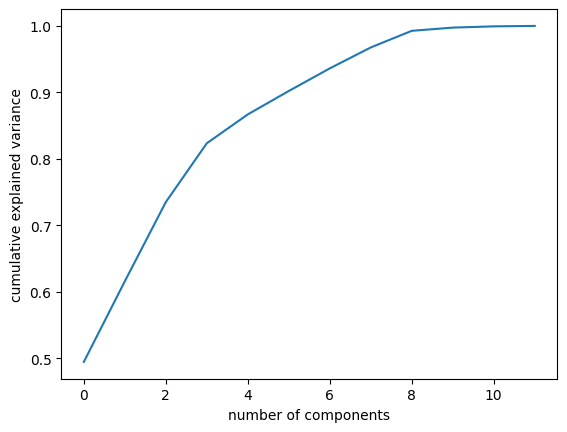

In [346]:
# Plot Cumulative Explained Variance
pca = PCA().fit(data_no_label)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("number of components")
plt.ylabel("cumulative explained variance")

In [347]:
# Select number of components
pca = PCA(9)
projected = pca.fit_transform(data_no_label)

In [348]:
# Number of rows and columns 
projected.shape

(1996, 9)

In [349]:
# Name new 9 columns 
data_pca = pd.DataFrame(projected, columns = ["C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8", "C9"])

In [350]:
# Check changes made
data_pca.head()

,C1,C2,C3,C4,C5,C6,C7,C8,C9
0,3.561287,0.037973,-0.926019,0.481106,0.440874,-0.319592,-0.554069,0.050011,-1.084948
1,-4.517271,1.188823,1.881781,0.588315,-0.540923,-0.167218,-0.060500,-0.631372,0.733918
2,-3.396221,-2.816056,-0.745652,1.006056,-0.854768,0.017429,-0.445608,-1.190075,-0.572390
3,-1.492387,0.806618,0.886941,0.151181,-0.013131,0.068922,0.561790,0.143610,1.016231
4,-3.455096,0.297086,-0.965248,1.319661,-0.167423,-0.484584,-0.801180,-1.014808,-1.447789


In [351]:
# Reset index to avoid missing values on target variable
data_pca["par_eur"] = y.reset_index(drop=True)

In [352]:
# Check indexes
data_pca.head()

,C1,C2,C3,C4,C5,C6,C7,C8,C9,par_eur
0,3.561287,0.037973,-0.926019,0.481106,0.440874,-0.319592,-0.554069,0.050011,-1.084948,201495.28
1,-4.517271,1.188823,1.881781,0.588315,-0.540923,-0.167218,-0.060500,-0.631372,0.733918,202484.46
2,-3.396221,-2.816056,-0.745652,1.006056,-0.854768,0.017429,-0.445608,-1.190075,-0.572390,107997.00
3,-1.492387,0.806618,0.886941,0.151181,-0.013131,0.068922,0.561790,0.143610,1.016231,188797.98
4,-3.455096,0.297086,-0.965248,1.319661,-0.167423,-0.484584,-0.801180,-1.014808,-1.447789,208188.97


In [353]:
type(data_pca)

pandas.core.frame.DataFrame

In [354]:
data_array = data_pca.values

In [355]:
type(data_array)

numpy.ndarray

# Regression model with PCA 
## Testing size 20%

In [356]:
# Select features (independent variables) and target (dependent variable)
X = data_pca.drop(columns=['par_eur'])  # Exclude target variable
y = data_pca['par_eur']  # Target variable

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)



In [357]:
# Models
models = {
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(n_estimators = 100, random_state = 42)
}

In [358]:
# Store results
results = []

# Train and evaluate models
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Append results to the list
    results.append([name, mae, mse, rmse, r2])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
print(results_df)

           Model          MAE           MSE          RMSE    R2 Score
0  Decision Tree  14136.27740  3.278930e+08  18107.814708    0.837751
1  Random Forest   9809.02076  1.499139e+08  12243.934193    0.925819


# Cross validation 
# Regression task 
## testing size 20%

In [359]:
# Store results
results = []

# Train and evaluate models using cross-validation for R² Score
for name, model in models.items():
    # Perform cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv = 10, scoring = 'r2')  # Using R² for scoring
    mean_cv_score = cv_scores.mean()  # Mean R² score
    
    # Train the model for predictions
    model.fit(X_train, y_train)
    
    # Store results
    results.append([name, mean_cv_score])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(results_df)


Model Performance Metrics using Cross-Validation for R² Score:
           Model  Mean CV R² Score
0  Decision Tree          0.804917
1  Random Forest          0.904987



Model Performance Metrics using Cross-Validation for R² Score:
           Model  Mean CV R² Score
0  Decision Tree          0.804917
1  Random Forest          0.904987


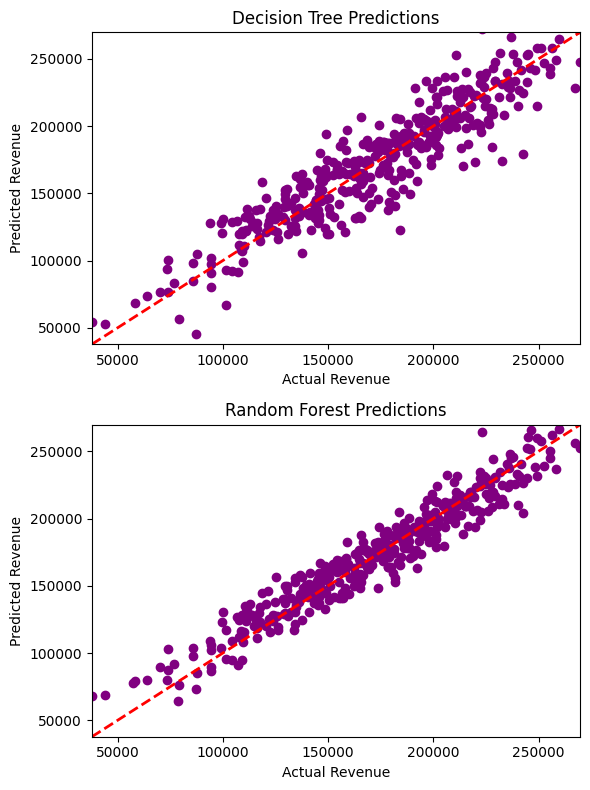

In [360]:
# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(results_df)

# Predict on the test set for final evaluation
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

# Plotting actual vs predicted for each model vertically
plt.figure(figsize=(6, 8))

for i, (name, y_pred) in enumerate(predictions.items()):
    plt.subplot(2, 1, i + 1)
    plt.scatter(y_test, y_pred, color='purple')
    plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],'r--',lw=2)
    plt.title(f'{name} Predictions')
    plt.xlabel('Actual Revenue')
    plt.ylabel('Predicted Revenue')
    plt.xlim(y_test.min(), y_test.max())
    plt.ylim(y_test.min(), y_test.max())

plt.tight_layout()
plt.show()

# Hyperparameter Tunnning using GridSearchCV
# Regression task 
## Testing size 20%

In [361]:
from sklearn.linear_model import Ridge  # Ridge for regularization
from sklearn.model_selection import GridSearchCV

# Select features (independent variables) and target (dependent variable)
# Select features (independent variables) and target (dependent variable)
X = data_pca.drop(columns=['par_eur'])  # Exclude target variable
y = data_pca['par_eur']  # Target variable

# Split the data into training and testing sets (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)



# Set up parameter grids for each model
param_grid = {
    'Decision Tree': {"max_depth": [None, 2, 10],    # Maximum depth of the tree
                      'min_samples_split': [2, 10]        # Minimum number of samples required 
                     },  
    'Random Forest': {'n_estimators': [25, 200],        # Number of trees in the forest.
                      'criterion': ["squared_error", "absolute_error"],   # Method used to evaluate the quality of a split.   
                      'max_depth': [10,15]       # Number of trees in the forest
                     }  
}

# Models: Linear Regression, Decision Tree, Random Forest
models = {
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(random_state = 42)
}

# Store results
results = []

# Grid Search for hyperparameter tuning
# Train the model with dimensionally reduced and scaled data
for name, model in models.items():
    grid_search = GridSearchCV(model, param_grid[name], cv = 10, scoring = 'r2')  # 5-fold CV for R²
    grid_search.fit(X_train, y_train)
    
    # Best parameters and best score
    best_params = grid_search.best_params_
    best_score  = grid_search.best_score_
    
    # Store results
    results.append([name, best_params, best_score])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Best Parameters", "Best CV R² Score"])
print("\nBest Hyperparameters and Scores from Grid Search:")
print(results_df)


Best Hyperparameters and Scores from Grid Search:
           Model                                    Best Parameters  \
0  Decision Tree         {'max_depth': 10, 'min_samples_split': 10}   
1  Random Forest  {'criterion': 'squared_error', 'max_depth': 15...   

   Best CV R² Score  
0          0.820672  
1          0.903317  


# Regression model with PCA 
## Testing size 30%

In [373]:
# Select features (independent variables) and target (dependent variable)
X = data_pca.drop(columns=['par_eur'])  # Exclude target variable
y = data_pca['par_eur']  # Target variable'

# Split the data into training and testing sets (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)



In [374]:
# Store results
results = []

# Train and evaluate models
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Append results to the list
    results.append([name, mae, mse, rmse, r2])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
print(results_df)

           Model          MAE           MSE          RMSE    R2 Score
0  Decision Tree  14062.53571  3.197064e+08  17880.334801    0.840990
1  Random Forest  10345.67614  1.682579e+08  12971.428095    0.916315


# Cross validation 
# Regression task
## Testing size 30%

In [375]:
# Store results
results = []

# Train and evaluate models using cross-validation for R² Score
for name, model in models.items():
    # Perform cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv = 10, scoring = 'r2')  # Using R² for scoring
    mean_cv_score = cv_scores.mean()  # Mean R² score
    
    # Train the model for predictions
    model.fit(X_train, y_train)
    
    # Store results
    results.append([name, mean_cv_score])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(results_df)


Model Performance Metrics using Cross-Validation for R² Score:
           Model  Mean CV R² Score
0  Decision Tree          0.786186
1  Random Forest          0.903284



Model Performance Metrics using Cross-Validation for R² Score:
           Model  Mean CV R² Score
0  Decision Tree          0.786186
1  Random Forest          0.903284


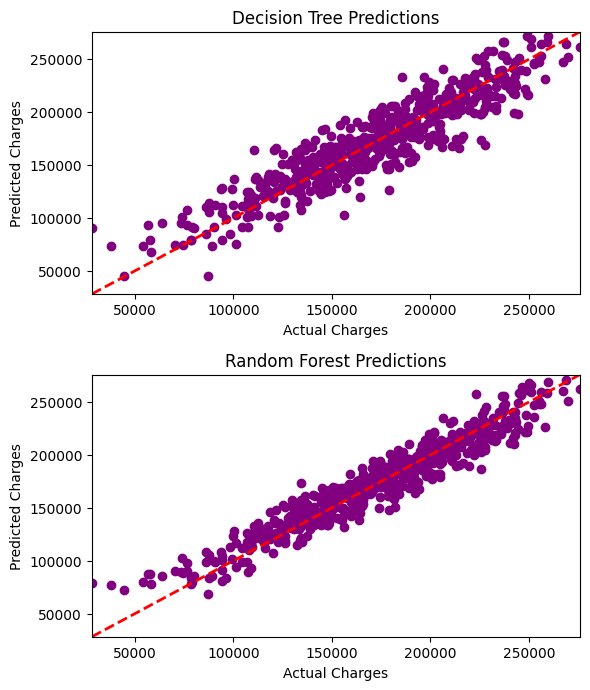

In [376]:
# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(results_df)

# Predict on the test set for final evaluation
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

# Plotting actual vs predicted for each model vertically with smaller size
plt.figure(figsize = (6, 10))  # Adjusted size for a more compact vertical layout

for i, (name, y_pred) in enumerate(predictions.items()):
    plt.subplot(3, 1, i + 1)  # 3 rows, 1 column
    plt.scatter(y_test, y_pred, color = 'purple')
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', color = 'red', lw = 2)  # Diagonal line
    plt.title(f'{name} Predictions')
    plt.xlabel('Actual Revenue')
    plt.ylabel('Predicted Revenue')
    plt.xlim(y_test.min(), y_test.max())
    plt.ylim(y_test.min(), y_test.max())

plt.tight_layout()
plt.show()

# Hyperparameter Tunnning using GridSearchCV
# Regression task 
## Testing size 30%

In [377]:
from sklearn.linear_model import Ridge  # Ridge for regularization
from sklearn.model_selection import GridSearchCV

# Select features (independent variables) and target (dependent variable)
# Select features (independent variables) and target (dependent variable)
X = data_pca.drop(columns=['par_eur'])  # Exclude target variable
y = data_pca['par_eur']  # Target variable

# Split the data into training and testing sets (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)



# Set up parameter grids for each model
param_grid = {
    'Decision Tree': {"max_depth": [None, 2, 10],         # Maximum depth of the tree.
                      'min_samples_split': [2, 10]          # Minimum number of samples required
                     },  
    'Random Forest': {'n_estimators': [25, 200],           # Number of trees in the forest.
                      'criterion': ["squared_error", "absolute_error"],   # Method used to evaluate the quality of a split.
                      'max_depth': [10,15]                              # Maximum depth of trees.
                     }  
}

# Models: Linear Regression, Decision Tree, Random Forest
models = {
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(random_state = 42)
}

# Store results
results = []

# Grid Search for hyperparameter tuning
# Train the model with dimensionally reduced and scaled data
for name, model in models.items():
    grid_search = GridSearchCV(model, param_grid[name], cv = 10, scoring = 'r2')  # 5-fold CV for R²
    grid_search.fit(X_train, y_train)
    
    # Best parameters and best score
    best_params = grid_search.best_params_
    best_score  = grid_search.best_score_
    
    # Store results
    results.append([name, best_params, best_score])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Best Parameters", "Best CV R² Score"])
print("\nBest Hyperparameters and Scores from Grid Search:")
print(results_df)


Best Hyperparameters and Scores from Grid Search:
           Model                                    Best Parameters  \
0  Decision Tree         {'max_depth': 10, 'min_samples_split': 10}   
1  Random Forest  {'criterion': 'squared_error', 'max_depth': 15...   

   Best CV R² Score  
0          0.820672  
1          0.903317  


# Model on unseen data 

In [378]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X = data.drop(columns=['par_eur']) # Select dependent variables
y = data['par_eur'] # Select target variable

# Split data
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.30,random_state=42)
# Select model
model = RandomForestRegressor(n_estimators=100,random_state=42)
#Fit the model
model.fit(X_train, y_train)
# Add dataframe to test model
new_data = pd.DataFrame([[8, 81077.05, 91.19, 6.95, 5.10, 7.10, 1.23, 4.12, 108112.88, 1.0, 1, 99.44]],columns=X.columns)
# Make a prediction of Revenue
new_pred = model.predict(new_data)
print("Predicted Annual Revenue:", round(new_pred[0], 2))

Predicted Annual Revenue: 277717.58


In [380]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

X = data.drop(columns=['par_eur']) #Drop target variable
y = data['par_eur'] # Select target variable
# Split data
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.30,random_state=42)
# Select model
model = DecisionTreeRegressor(random_state=42)
# Fit the model
model.fit(X_train, y_train)
# Add DataFrame to test model
new_data = pd.DataFrame([[8, 81077.05, 91.19, 6.95, 5.10, 7.10, 1.23, 4.12, 108112.88, 1.0, 1, 99.44]],columns=X.columns)
# Make a prediction of Revenue
new_pred = model.predict(new_data)
print("Predicted Annual Revenue:",
      round(new_pred[0], 2))

Predicted Annual Revenue: 280904.46


# PCA for Classification

In [566]:
# Reset index to avoid missing values at PCA
data = data.reset_index(drop=True)
# Select target and independent variables
X = data.drop(columns=['ed_level'])
y= data['ed_level']

In [567]:
# Drop target variable
data_no_label2 = data.drop(columns = ["ed_level"])

In [568]:
# Original data and ata shape 
data_no_label2.shape, data.shape

((1996, 12), (1996, 13))

In [569]:
# Check first 5 rows
data_no_label2.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ves_type,sus_score,par_eur
0,8,0.540898,-0.444359,0.503282,-0.436984,0.025445,-1.028259,-0.264253,-0.063615,1,-0.130120,201495.28
1,0,0.218485,-0.040629,0.785662,1.152712,-0.452926,0.484959,-0.285973,0.089532,4,0.395078,202484.46
2,1,-1.426534,-0.406541,0.826002,-1.093374,-1.531807,0.240656,-0.644344,0.728768,1,-1.400640,107997.00
3,3,0.035143,0.492909,0.170477,0.547602,0.279898,0.707384,0.257014,-0.010075,3,0.410585,188797.98
4,1,0.566387,-0.664111,0.891555,0.234791,-0.692112,-1.112124,-1.111312,1.114125,1,-0.015506,208188.97


Text(0, 0.5, 'cumulative explained variance')

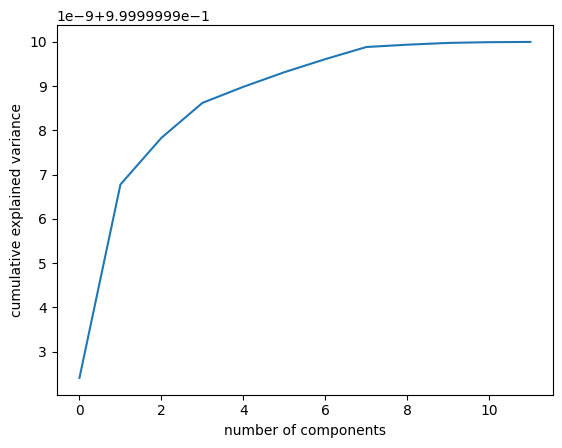

In [570]:
# Fit PCA
pca = PCA().fit(data_no_label2)
# Plot cumulative variance
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("number of components")
plt.ylabel("cumulative explained variance")

In [571]:
# Select 9 components
pca = PCA(9)
# Fit model
projected2 = pca.fit_transform(data_no_label2)

In [572]:
# Shape of the new model
projected2.shape

(1996, 9)

In [573]:
# Name the 9 new columns
data_pca2 = pd.DataFrame(projected, columns = ["C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8", "C9"])

In [574]:
# Check changes
data_pca2.head()

,C1,C2,C3,C4,C5,C6,C7,C8,C9
0,3.561287,0.037973,-0.926019,0.481106,0.440874,-0.319592,-0.554069,0.050011,-1.084948
1,-4.517271,1.188823,1.881781,0.588315,-0.540923,-0.167218,-0.060500,-0.631372,0.733918
2,-3.396221,-2.816056,-0.745652,1.006056,-0.854768,0.017429,-0.445608,-1.190075,-0.572390
3,-1.492387,0.806618,0.886941,0.151181,-0.013131,0.068922,0.561790,0.143610,1.016231
4,-3.455096,0.297086,-0.965248,1.319661,-0.167423,-0.484584,-0.801180,-1.014808,-1.447789


In [575]:
# Reset index to avoid missing values
data_pca2["ed_level"] = y.reset_index(drop=True)

In [576]:
# Check changes 
data_pca2.head()

,C1,C2,C3,C4,C5,C6,C7,C8,C9,ed_level
0,3.561287,0.037973,-0.926019,0.481106,0.440874,-0.319592,-0.554069,0.050011,-1.084948,1.0
1,-4.517271,1.188823,1.881781,0.588315,-0.540923,-0.167218,-0.060500,-0.631372,0.733918,0.0
2,-3.396221,-2.816056,-0.745652,1.006056,-0.854768,0.017429,-0.445608,-1.190075,-0.572390,2.0
3,-1.492387,0.806618,0.886941,0.151181,-0.013131,0.068922,0.561790,0.143610,1.016231,0.0
4,-3.455096,0.297086,-0.965248,1.319661,-0.167423,-0.484584,-0.801180,-1.014808,-1.447789,1.0


In [577]:
# Data type
type(data_pca2)

pandas.core.frame.DataFrame

In [578]:
# Change data type to array
data_array2 = data_pca2.values

In [579]:
type(data_array2)

numpy.ndarray

# Classification model with PCA
### Testing size 20%

In [580]:
# Define features and target variable
X = data_pca2.drop(columns='ed_level')  # Features
y = data_pca2['ed_level']   # target variable

In [581]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [582]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [583]:
# Train and evaluate ML model classifiers 
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [584]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision  Recall  F1 Score
0     k-Nearest Neighbors    0.9825   0.982475  0.9825  0.982478
1           Decision Tree    0.9500   0.949935  0.9500  0.949922
2           Random Forest    0.9975   0.997525  0.9975  0.997501
3     Logistic Regression    1.0000   1.000000  1.0000  1.000000
4  Support Vector Machine    1.0000   1.000000  1.0000  1.000000


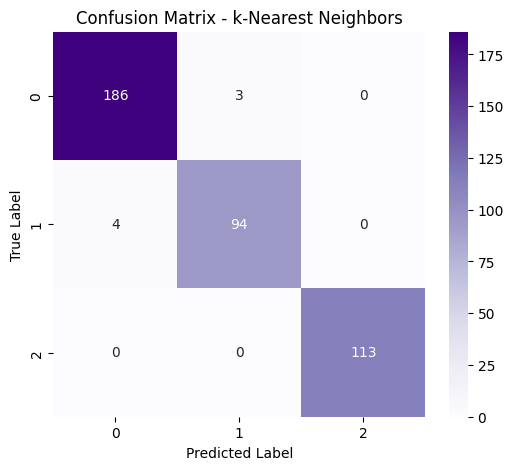

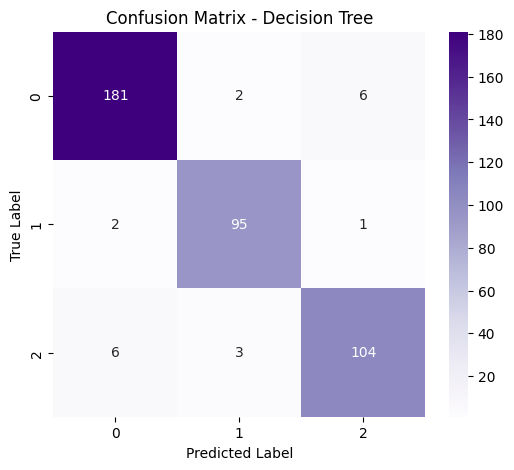

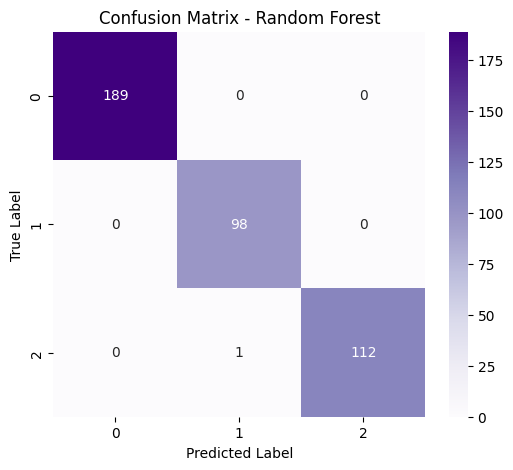

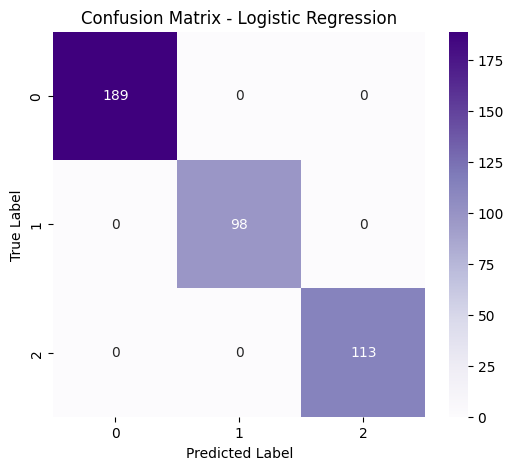

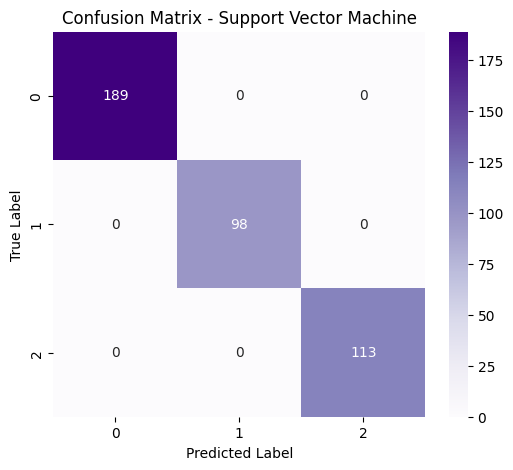

In [585]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix for each classifier
for name, classifier in classifiers.items():

    # Train model
    classifier.fit(X_train, y_train)

    # Predict test set
    y_pred = classifier.predict(X_test)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot
    plt.figure(figsize=(6,5))

    sns.heatmap(cm,annot=True,fmt='d',cmap='Purples')

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    plt.show()

# Classification model with PCA
### Testing size 30%

In [586]:
# Define features and target variable
X = data_pca2.drop(columns='ed_level')  # Features
y = data_pca2['ed_level']   #target variable

In [587]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [588]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [589]:
# Train and evaluate ML model classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [590]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.981636   0.981674  0.981636  0.981651
1           Decision Tree  0.953255   0.953530  0.953255  0.953306
2           Random Forest  0.994992   0.995014  0.994992  0.994999
3     Logistic Regression  1.000000   1.000000  1.000000  1.000000
4  Support Vector Machine  1.000000   1.000000  1.000000  1.000000


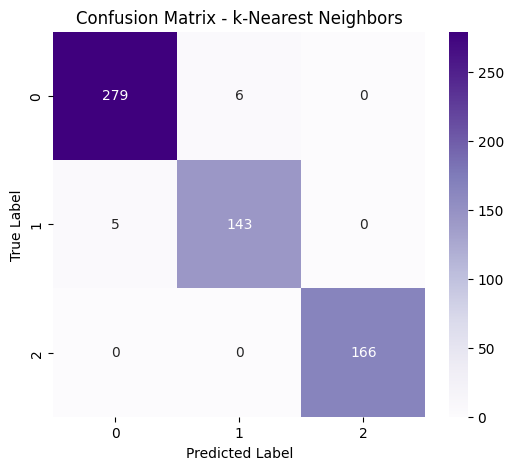

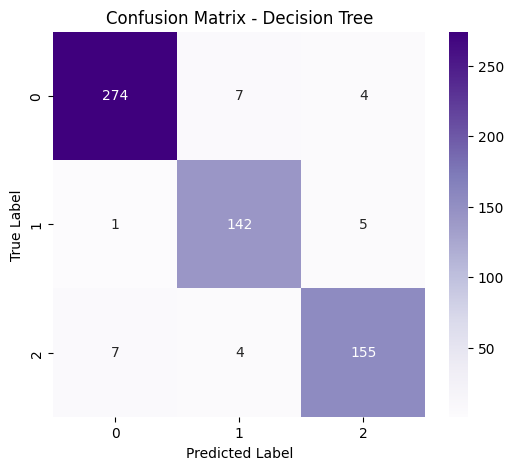

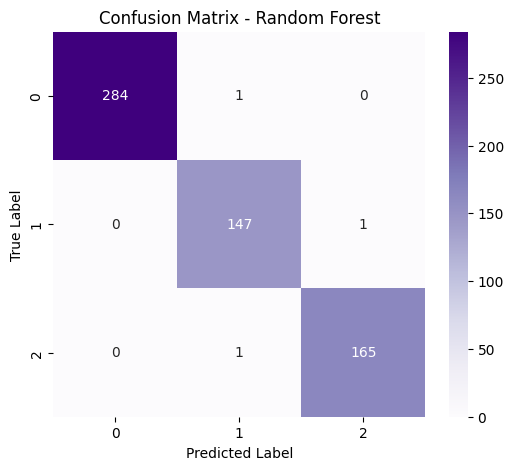

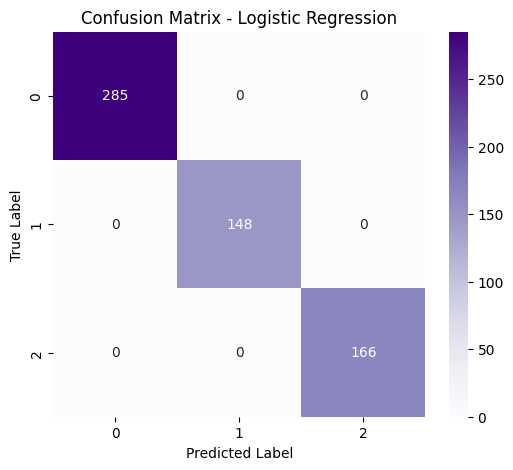

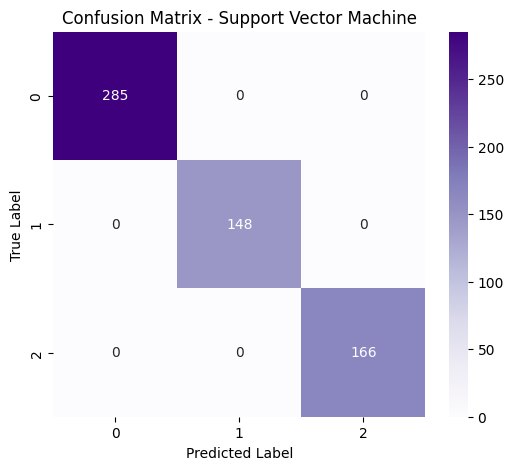

In [591]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix for each classifier
for name, classifier in classifiers.items():

    # Train model
    classifier.fit(X_train, y_train)

    # Predict test set
    y_pred = classifier.predict(X_test)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot
    plt.figure(figsize=(6,5))

    sns.heatmap(cm,annot=True,fmt='d',cmap='Purples')

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    plt.show()

# LDA for Classification

In [426]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

In [427]:
# Reset index to avoid missing values 
data = data.reset_index(drop=True)
# Select features and target variable
X = data.drop(columns=['ed_level'])
y= data['ed_level']

In [428]:
# Name model lds
lda=LinearDiscriminantAnalysis()
# Fit and transform the model
X_lda=lda.fit_transform(X,y)

In [429]:
# New shape, the number of categories minus one
X_lda.shape

(1996, 2)

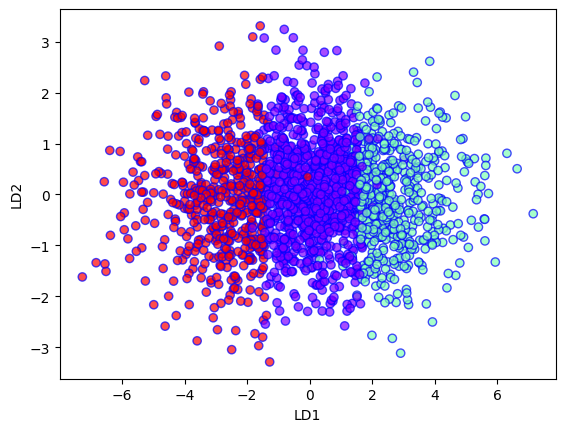

In [430]:
# Plot the classes
plt.xlabel('LD1')
plt.ylabel('LD2')
plt.scatter(
    X_lda[:,0],
    X_lda[:,1],
    c=y,
    cmap='rainbow',
    alpha=0.7,
    edgecolors='b'
)

# Logistic Regression with LDA
### Testing size 20%

In [431]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [432]:
# Split data in testing and training
X_train, X_test, y_train, y_test = train_test_split(X_lda, y, test_size= 0.2, random_state=42)
# Slect model
model = LogisticRegression()
# Fit the model
model.fit(X_train, y_train)
pred = model.predict(X_test)

<Axes: >

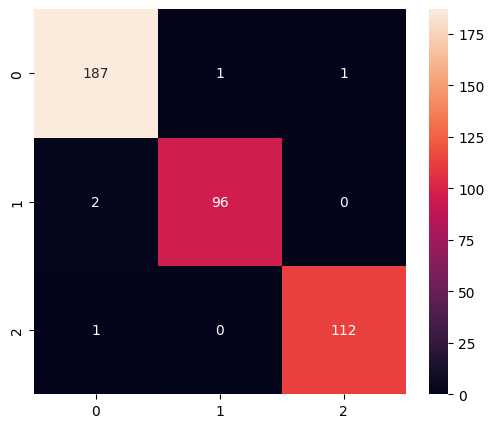

In [433]:
# Plot confussion matrix of predictions
y_predict = model.predict(X_test)
cm = confusion_matrix(y_test, y_predict)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot = True, fmt = 'd')

In [434]:
#Print accuracy and confussion matrix 
print(accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))

0.9875
[[187   1   1]
 [  2  96   0]
 [  1   0 112]]


#### USE THE MODEL OF UNSEEN DATA IN TRAINED MODEL

In [435]:
# Dataframe to test the predictions
new_data = pd.DataFrame([[8, 81077.05, 91.19, 6.95, 5.10, 7.10, 1.23, 4.12, 108112.8, 1, 99.44, 201495.28]])

In [436]:
# See DataFrame
new_data

,0,1,2,3,4,5,6,7,8,9,10,11
0,8,81077.05,91.19,6.95,5.1,7.1,1.23,4.12,108112.8,1,99.44,201495.28


In [437]:
# tansform new data to lda
gen = lda.transform(new_data)

In [438]:
# Shape of new data
gen.shape

(1, 2)

In [439]:
# Make a prediction of class for new data
new_pred = model.predict(gen)

In [440]:
# Print class predicted
new_pred

array([1.])

# Comparison of models with LDA
### Testing size 20%

In [441]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_lda, y, test_size= 0.2, random_state=42)

In [442]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}


In [443]:
# Train and evaluate ML model classifiers 
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [444]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision  Recall  F1 Score
0     k-Nearest Neighbors    0.9700   0.970015  0.9700  0.969961
1           Decision Tree    0.9650   0.965368  0.9650  0.965058
2           Random Forest    0.9825   0.982861  0.9825  0.982505
3     Logistic Regression    0.9875   0.987514  0.9875  0.987497
4  Support Vector Machine    0.9825   0.982621  0.9825  0.982501


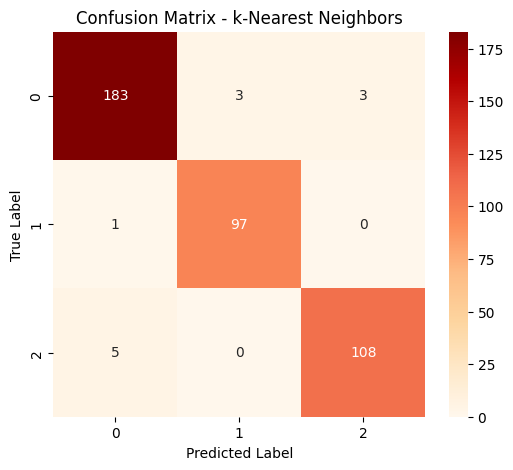

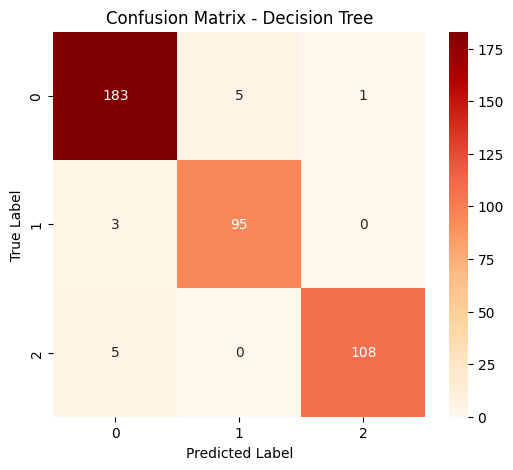

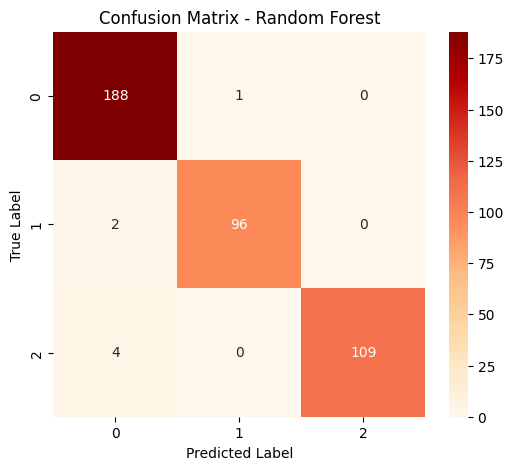

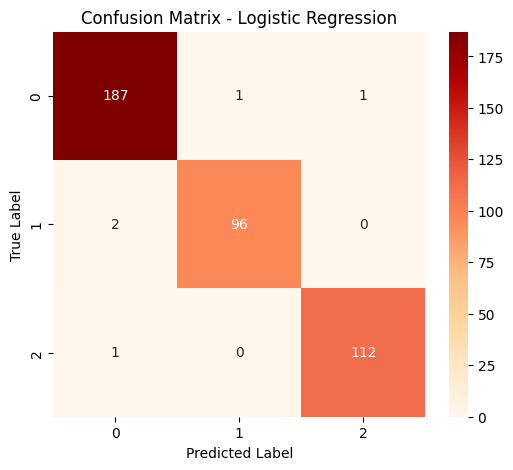

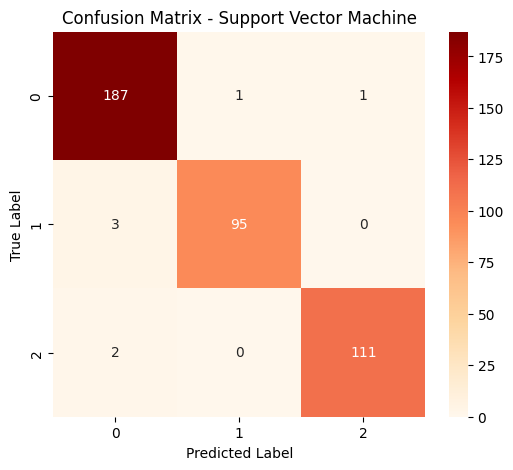

In [445]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Plot confusion matrix for each classifier
for name, classifier in classifiers.items():

    # Train the classifier
    classifier.fit(X_train, y_train)

    # Predict on the test set
    y_pred = classifier.predict(X_test)

    # Create confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix
    plt.figure(figsize=(6,5))

    sns.heatmap(cm,annot=True,fmt='d',cmap='OrRd')

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    plt.show()

# Comparison of models with LDA
### Testing size 30%

In [446]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_lda, y, test_size= 0.3, random_state=42)

In [447]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}


In [448]:
# Train and evaluate ML model classifiers 
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [449]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.968280   0.968287  0.968280  0.968249
1           Decision Tree  0.959933   0.959961  0.959933  0.959942
2           Random Forest  0.978297   0.978347  0.978297  0.978296
3     Logistic Regression  0.976628   0.976596  0.976628  0.976591
4  Support Vector Machine  0.974958   0.974926  0.974958  0.974906


# Confussion matrix 

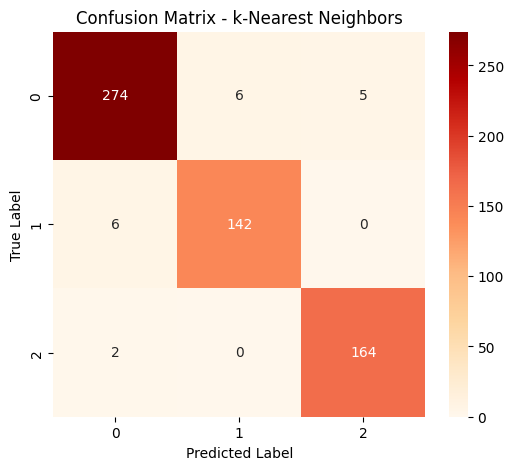

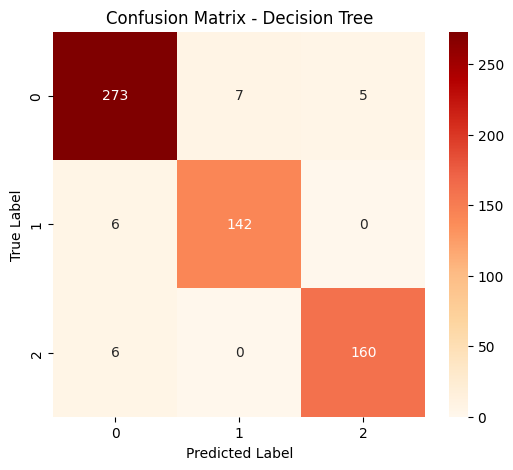

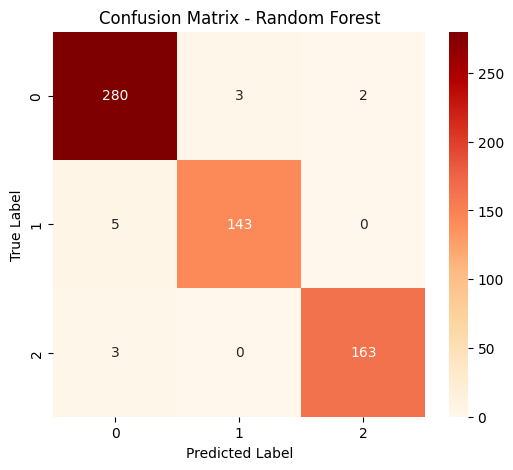

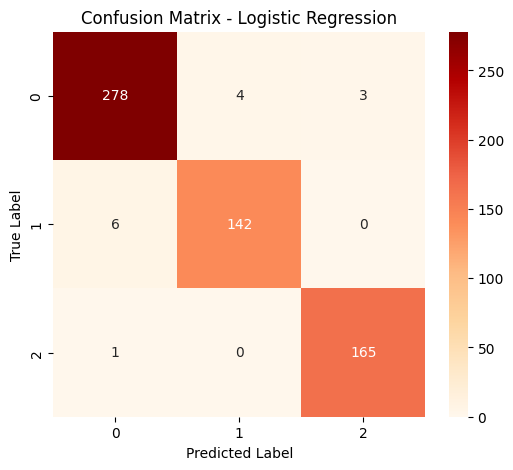

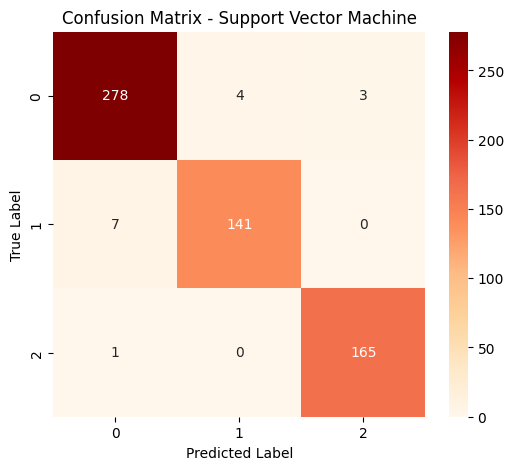

In [450]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Plot confusion matrix for each classifier
for name, classifier in classifiers.items():

    # Train the classifier
    classifier.fit(X_train, y_train)

    # Predict on the test set
    y_pred = classifier.predict(X_test)

    # Create confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix
    plt.figure(figsize=(6,5))

    sns.heatmap(cm,annot=True,fmt='d',cmap='OrRd')

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    plt.show()

# Apply SMOTE to balance the training dataset

In [362]:
X= data.drop(columns = 'ed_level') # Drop target variable
y = data['ed_level']               # Target variable

In [367]:
# Check first 5 rows
data.head()

,County,afi_eur,fc_index,pa_score,fs_index,wq_score,wr_index,ifr_percen,ai_eur,ed_level,ves_type,sus_score,par_eur
0,8,0.536354,-0.447542,0.497503,-0.434460,0.040816,-1.033088,-0.268116,-0.063137,1.0,1,-0.125963,201495.28
1,0,0.219032,-0.047136,0.780367,1.147735,-0.438776,0.492647,-0.289855,0.088280,0.0,4,0.395980,202484.46
2,1,-1.400013,-0.410035,0.820776,-1.087753,-1.520408,0.246324,-0.648551,0.720294,2.0,1,-1.388610,107997.00
3,3,0.038585,0.482007,0.164128,0.545480,0.295918,0.716912,0.253623,-0.010201,0.0,3,0.411390,188797.98
4,1,0.561440,-0.665484,0.886441,0.234145,-0.678571,-1.117647,-1.115942,1.101297,1.0,1,-0.012060,208188.97


In [108]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [364]:
# Show count of each class in the target variable
class_counts = y_train.value_counts()
print("Count of each class in 'ed_level':")
print(class_counts)

Count of each class in 'ed_level':
ed_level
0.0    692
2.0    391
1.0    377
Name: count, dtype: int64


In [365]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance the classes in the training set
smote = SMOTE(random_state=42)
XS_train, ys_train = smote.fit_resample(X_train, y_train)

In [366]:
# Show count of each class in the target variable
class_counts = ys_train.value_counts()
print("Count of each class in 'ed_level':")
print(class_counts)

Count of each class in 'ed_level':
ed_level
2.0    692
0.0    692
1.0    692
Name: count, dtype: int64


In [368]:
# Train and evaluate classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(XS_train, ys_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [369]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.616438   0.617919  0.616438  0.616500
1           Decision Tree  0.764384   0.764570  0.764384  0.764454
2           Random Forest  0.884932   0.885395  0.884932  0.885011
3     Logistic Regression  0.934247   0.935623  0.934247  0.934353
4  Support Vector Machine  0.706849   0.715127  0.706849  0.705105


# Near miss

In [105]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score
from imblearn.under_sampling import NearMiss
import warnings
warnings.filterwarnings('ignore') # We can suppress the warnings

In [106]:
X= data.drop(columns = 'ed_level') # Drop target variable
y = data['ed_level']        # Target variable

In [109]:
# Show count of each class in the target variable
np.bincount(y_train)

array([758, 411, 427])

In [110]:
# NearMiss
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, stratify=y)

# Create an object by calling a method NearMiss()
nr = NearMiss()

# Train the model
X_train, y_train = nr.fit_resample(X_train, y_train)

In [111]:
# Show count of each class in the target variable after fitting the model
np.bincount(y_train)

array([382, 382, 382])

In [115]:
# Define classifiers for ML models
classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}


In [116]:
# Train and evaluate classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [119]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0        Decision Tree  0.715431   0.751725  0.715431  0.703543
1        Random Forest  0.771543   0.817878  0.771543  0.766396
2  Logistic Regression  0.885772   0.904512  0.885772  0.884794


# XGBoost

In [120]:
from xgboost import XGBClassifier

In [121]:
X= data.drop(columns = 'ed_level') # Drop target variable
y = data['ed_level']        Target variable

In [122]:
# Show count of each class in the target variable after NEAR MISS
np.bincount(y_train)

array([382, 382, 382])

In [123]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, stratify=y) 

# Create an object by calling XGBoost Classifier
xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42, eval_metric='mlogloss')

# Create an object by calling a method NearMiss()
nr = NearMiss()

# Train the model
X_train, y_train = nr.fit_resample(X_train, y_train)

In [124]:
np.bincount(y_train)

array([382, 382, 382])

In [125]:
# Train the model
xgb.fit(X_train, y_train)

# Predict on the test set
y_pred = xgb.predict(X_test)

In [126]:
# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test,y_pred,output_dict=True,zero_division=0)

precision = report['weighted avg']['precision']
recall = report['weighted avg']['recall']
f1_score_value = report['weighted avg']['f1-score']

In [127]:
# Store results
xgb_results = [["XGBoost Classifier",accuracy,precision,recall,f1_score_value]]


In [128]:
# Convert results to DataFrame
xgb_results_df = pd.DataFrame(xgb_results,columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])

print("XGBoost Performance Metrics on Test Set:")
print(xgb_results_df)

XGBoost Performance Metrics on Test Set:
                Model  Accuracy  Precision    Recall  F1 Score
0  XGBoost Classifier  0.785571   0.835285  0.785571  0.780054


<Axes: >

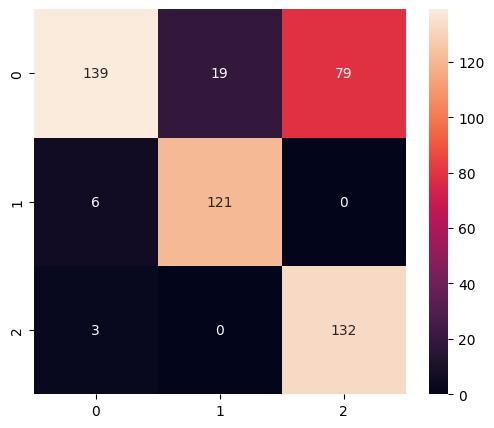

In [130]:
# Plot confussion matrix for XGBoost
y_predict = xgb.predict(X_test)
cm = confusion_matrix(y_test, y_predict)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot = True, fmt = 'd')

# Develop a GridSearhCV for 3 classification models
### k-fold10

In [451]:
X= data.drop(columns = 'ed_level') # Drop target variable
y = data['ed_level']  # Target variable

In [452]:
# Select classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

In [453]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=10, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                 Model  Mean CV Accuracy
0  Logistic Regression          0.920857
1        Decision Tree          0.787621
2        Random Forest          0.878281


In [454]:
X= data.drop(columns = 'ed_level') # Drop target variable
y = data['ed_level']  #target variable
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.30,random_state=42, stratify=y)


In [455]:
# Select classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

In [456]:
# Define hyperparameter grids for each classifier
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10],             # Strength of regularization.
        "solver": ['lbfgs', 'liblinear'],  # Algorithm used to optimize Logistic Regression.
    },
    "Decision Tree": {
        "max_depth": [None, 2, 4],       # Maximum depth of the tree.
        'min_samples_split': [2, 10]       # Minimum number of samples required
    },
    "Random Forest": {
        "n_estimators": [100, 200],       # Number of trees in the forest.
        "criterion": ['gini', 'entropy'],  # Function used to measure split quality.
        "max_depth": [None, 10, 20, 30],   # Maximum depth of trees.
}}

In [457]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 10, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])

Running GridSearchCV for Logistic Regression...
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Running GridSearchCV for Decision Tree...
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Running GridSearchCV for Random Forest...
Fitting 10 folds for each of 16 candidates, totalling 160 fits


In [458]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
                 Model  Accuracy  Precision    Recall  F1 Score  \
0  Logistic Regression  0.946578   0.946827  0.946578  0.946614   
1        Decision Tree  0.801336   0.801201  0.801336  0.801238   
2        Random Forest  0.889816   0.893840  0.889816  0.889866   

                                     Best Parameters  
0                        {'C': 1, 'solver': 'lbfgs'}  
1        {'max_depth': None, 'min_samples_split': 2}  
2  {'criterion': 'gini', 'max_depth': None, 'n_es...  


In [459]:
# Cross-validation for accuracy on the full dataset using best models
cv_results = []
for name, classifier in classifiers.items():
    # Get the best model from GridSearchCV
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv=10, n_jobs=-1, verbose=2)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    
    cv_scores = cross_val_score(best_model, X, y, cv=10, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

Fitting 10 folds for each of 6 candidates, totalling 60 fits
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Fitting 10 folds for each of 16 candidates, totalling 160 fits


In [460]:
# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores after GridSearchCV:")
print(cv_results_df)


Cross-Validation Accuracy Scores after GridSearchCV:
                 Model  Mean CV Accuracy
0  Logistic Regression          0.920857
1        Decision Tree          0.787621
2        Random Forest          0.878281


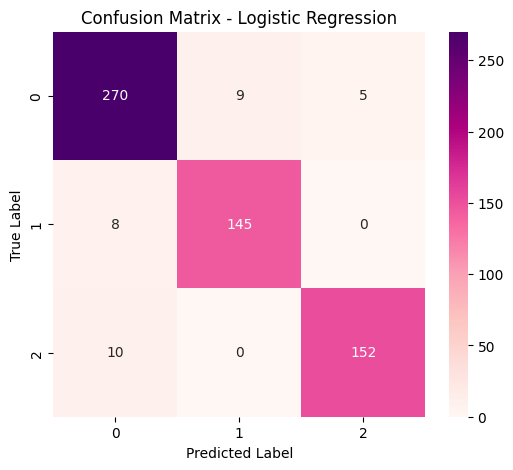

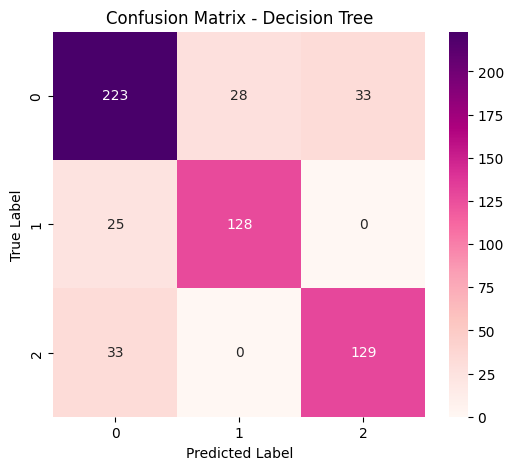

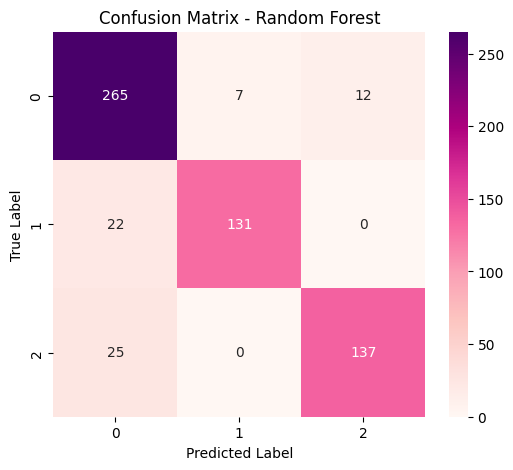

In [461]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix for each classifier
for name, classifier in classifiers.items():

    # GridSearchCV
    grid_search = GridSearchCV(estimator=classifier,param_grid=param_grids[name],cv=10,scoring='accuracy',n_jobs=-1)

    # Train model
    grid_search.fit(X_train, y_train)

    # Best tuned model
    best_model = grid_search.best_estimator_

    # Predict test set
    y_pred = best_model.predict(X_test)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot
    plt.figure(figsize=(6,5))

    sns.heatmap(cm,annot=True,fmt='d',cmap='RdPu')

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    plt.show()

<Figure size 800x500 with 0 Axes>

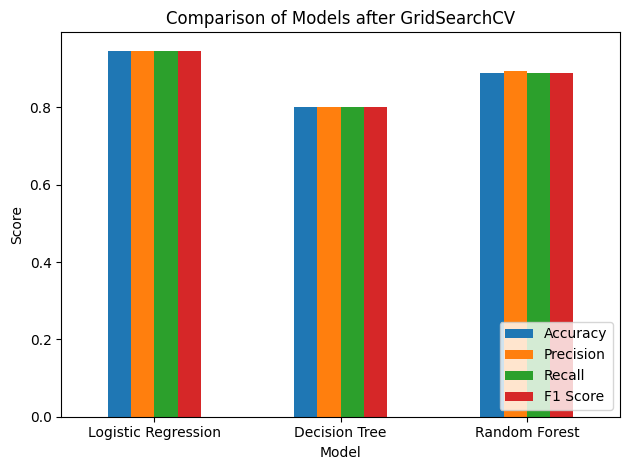

In [462]:
# Comparison of models after GridSearchCV
metrics_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])

# Select only performance metrics
plot_data = metrics_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']]

# Plot comparison
plt.figure(figsize=(8,5))
plot_data.plot(kind='bar')

plt.title('Comparison of Models after GridSearchCV')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=0)

plt.legend(loc='lower right')

plt.tight_layout()
plt.show()